# Prostate Tissue Classification

**Author:** Winston Nji
**Project:** ALU Capstone, Gleason Grading via Transfer Learning

This notebook runs every experiment end-to-end in the following order:

1. MobileNetV3-Small ablation (Exp A-F) on clean SICAPv2 data
2. MobileNet degradation training using the best clean config
3. ShuffleNetV2-x1.0 ablation (Exp A-F) on clean data
4. ShuffleNet degradation training using the best clean config
5. Zurich TMA cross-dataset evaluation: all 4 models x 9 conditions

**Design:** hit *Run All* and walk away, every cell reads what it needs
from `results_registry.json` and writes its result back.

## 1. Environment Setup

Install third-party libraries and mount Google Drive.

In [ ]:
!pip install -q timm openpyxl

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Imports

In [ ]:
import os, json, random, copy, warnings
from pathlib import Path
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as tvm
import timm

from sklearn.metrics import f1_score, classification_report, confusion_matrix

warnings.filterwarnings('ignore')

print(f'PyTorch : {torch.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {DEVICE}')

PyTorch : 2.11.0+cu130
CUDA    : True
Device  : cuda


## 3. Paths

All filesystem references are centralised here. Changing a root location requires editing only this cell.

In [ ]:
BASE        = Path('/content/drive/MyDrive/capstone')
SICAP_ROOT  = BASE / 'SICAPv2'
SICAP_IMGS  = SICAP_ROOT / 'images'
WSI_LABELS  = SICAP_ROOT / 'wsi_labels.xlsx'
DEVELOP_CSV = SICAP_ROOT / 'partition' / 'manifest_train.csv'
BENCH_CSV   = SICAP_ROOT / 'partition' / 'manifest_val.csv'

ZURICH_ROOT = BASE / 'zurich_data'
ZURICH_IMGS = ZURICH_ROOT / 'images'
ZURICH_CSV  = ZURICH_ROOT / 'manifest.csv'

# Experiment outputs
EMPIRICAL_DIR = BASE / 'checkpoints' / 'empirical'
CKPT_DIR      = EMPIRICAL_DIR / 'ckpts'
REGISTRY_PATH = EMPIRICAL_DIR / 'results_registry.json'

EMPIRICAL_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

print('Paths configured.')
print(f'  Checkpoints : {CKPT_DIR}')
print(f'  Registry    : {REGISTRY_PATH}')

Paths configured.
  Checkpoints : /content/drive/MyDrive/capstone/checkpoints/empirical/ckpts
  Registry    : /content/drive/MyDrive/capstone/checkpoints/empirical/results_registry.json


## 4. Configuration

Global hyper-parameters and the six ablation configurations are defined in one place. The 15 validation patient IDs are locked here and never seen during training.

In [ ]:
CLASS_NAMES  = ['NC', 'G3', 'G4', 'G5']
NUM_CLASSES  = 4
LABEL_MAP    = {'NC': 0, 'G3': 1, 'G4': 2, 'G5': 3}
IMG_SIZE     = 224
BATCH_SIZE   = 32
NUM_WORKERS  = 0
SEED         = 42   # single seed per experiment

WARMUP_EPOCHS   = 2
FINETUNE_EPOCHS = 20
ES_PATIENCE     = 5
LR_FACTOR       = 0.5
LR_PATIENCE     = 3
LR_MIN          = 1e-7

# 15 locked validation patients, must NOT appear in training split
# IDs match the patient_id column in wsi_labels.xlsx after int -> str conversion
VALIDATION_PATIENTS = [
    '122718', '192819', '235186', '269037', '360393',
    '378497', '385738', '609344', '648930', '667360',
    '708946', '747731', '768135', '775682', '780499',
]

# === Ablation grid ===
# Each config isolates the contribution of one component relative to the prior experiment.
#   pretrained        : use ImageNet weights (False = random init)
#   weight_decay      : L2 regularisation passed to Adam
#   drop_rate         : dropout before the final classification layer
#   use_class_weights : inverse-frequency weighting in CrossEntropyLoss
EXPERIMENT_CONFIGS = {
    'ExpA': {
        'pretrained': False, 'weight_decay': 0.0,
        'drop_rate': 0.0, 'use_class_weights': False,
        'label': 'No pretrain -- random init, no regularisation, uniform loss',
    },
    'ExpB': {
        'pretrained': True, 'weight_decay': 0.0,
        'drop_rate': 0.0, 'use_class_weights': False,
        'label': 'Pretrained only -- ImageNet weights, no regularisation',
    },
    'ExpC': {
        'pretrained': True, 'weight_decay': 1e-4,
        'drop_rate': 0.3, 'use_class_weights': False,
        'label': 'Pretrained + regularisation (weight_decay=1e-4, drop_rate=0.3)',
    },
    'ExpD': {
        'pretrained': True, 'weight_decay': 0.0,
        'drop_rate': 0.0, 'use_class_weights': True,
        'label': 'Pretrained + class-weighted loss',
    },
    'ExpE': {
        'pretrained': True, 'weight_decay': 1e-4,
        'drop_rate': 0.3, 'use_class_weights': True,
        'label': 'Pretrained + regularisation + class-weighted loss (full config)',
    },
    'ExpF': {
      'pretrained': True, 'weight_decay': 1e-4,
      'drop_rate': 0.3, 'use_class_weights': True,
      'dense_head': True,
      'label': 'Full config + dense projection head (576 → 256 → ReLU → dropout → 4)',
    },
}

print('Experiment grid:')
for name, cfg in EXPERIMENT_CONFIGS.items():
    print(f'  {name}: {cfg["label"]}')

Experiment grid:
  ExpA: No pretrain -- random init, no regularisation, uniform loss
  ExpB: Pretrained only -- ImageNet weights, no regularisation
  ExpC: Pretrained + regularisation (weight_decay=1e-4, drop_rate=0.3)
  ExpD: Pretrained + class-weighted loss
  ExpE: Pretrained + regularisation + class-weighted loss (full config)
  ExpF: Full config + dense projection head (576 → 256 → ReLU → dropout → 4)


## 5. Path Verification

Fail fast: raise a `FileNotFoundError` before any training starts if a required file or directory is missing.

In [ ]:
# =======================
# Check that every required path exists before any computation.
# This surfaces Drive mounting or folder naming issues early.
required = {
    "SICAP images dir" : SICAP_IMGS,
    "WSI labels Excel" : WSI_LABELS,
    "Development CSV"  : DEVELOP_CSV,
    "Benchmark CSV"    : BENCH_CSV,
    "Zurich images dir": ZURICH_IMGS,
    "Zurich CSV"       : ZURICH_CSV,
}

all_ok = True
for name, p in required.items():
    ok = p.exists()
    status = "OK     " if ok else "MISSING"
    print(f"  {status}  {name}: {p}")
    if not ok:
        all_ok = False

if all_ok:
    print("\nAll required paths found.")
else:
    raise FileNotFoundError("Resolve the MISSING paths above before continuing.")

  OK       SICAP images dir: /content/drive/MyDrive/capstone/SICAPv2/images
  OK       WSI labels Excel: /content/drive/MyDrive/capstone/SICAPv2/wsi_labels.xlsx
  OK       Development CSV: /content/drive/MyDrive/capstone/SICAPv2/partition/manifest_train.csv
  OK       Benchmark CSV: /content/drive/MyDrive/capstone/SICAPv2/partition/manifest_val.csv
  OK       Zurich images dir: /content/drive/MyDrive/capstone/zurich_data/images
  OK       Zurich CSV: /content/drive/MyDrive/capstone/zurich_data/manifest.csv

All required paths found.


## 6. Data Loading and Patient Split

Load the SICAPv2 patch manifests and enforce a strict patient-level split.

**Why both CSV files?** The VALIDATION_PATIENTS IDs were selected across the full
dataset, so some validation patients land in `manifest_val.csv`. Loading only
`manifest_train.csv` produces an empty validation set. Both files are merged first,
then the patient split is applied.

**Why `wsi_labels.xlsx`?** The CSV manifests may contain a `patient_id` column with
a different ID scheme (e.g. `'16B0003394'`) that does not match `wsi_labels.xlsx`
or VALIDATION_PATIENTS. The Excel file is the authoritative source; `slide_id` is
derived from `image_name` and used as the join key.

Combined development set: 9,959 patches
Patient IDs derived from wsi_labels.xlsx
Unique patients in combined set: 74

Train : 8,002 patches from 59 patients
Val   : 1,957 patches from 15 patients

Train label counts:
label
NC    3025
G3    1507
G4    2893
G5     577
Name: count, dtype: int64

Val label counts:
label
NC    748
G3    322
G4    748
G5    139
Name: count, dtype: int64


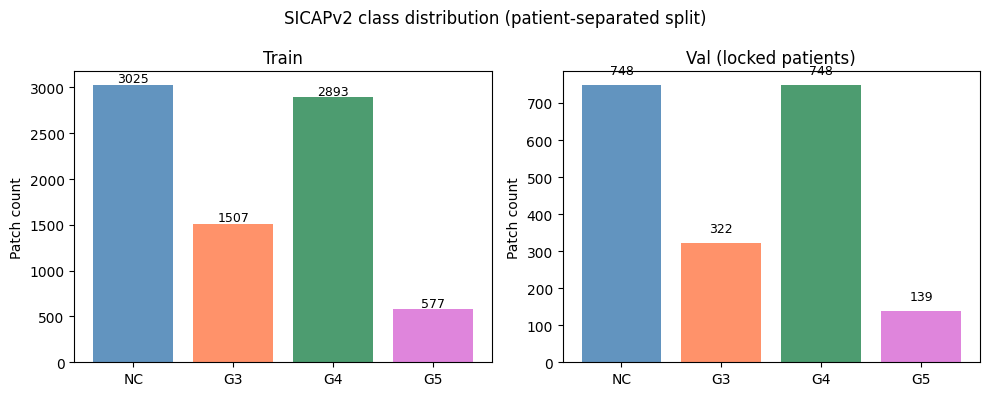

In [ ]:
# ===========================
# Step 1: Load both partition manifests and combine into one development pool.
# manifest_train.csv and manifest_val.csv are the SICAPv2 release splits, but
# the VALIDATION_PATIENTS list was selected across the entire dataset, so some
# of those patients land in manifest_val.csv. Loading only manifest_train.csv
# produces an empty validation set. Combining both files first, then applying
# the patient split, gives the correct train/val partition.
develop_df = pd.concat([
    pd.read_csv(DEVELOP_CSV),
    pd.read_csv(BENCH_CSV),
], ignore_index=True)
print(f"Combined development set: {len(develop_df):,} patches")

# == Step 2: Derive patient_id from wsi_labels.xlsx (authoritative source).
# The CSV manifests may contain a patient_id column with a different ID scheme
# (e.g. '16B0003394') that does not match wsi_labels.xlsx or VALIDATION_PATIENTS.
# Dropping any pre-existing patient_id column first forces the authoritative
# Excel lookup every time and avoids a silent mismatch.
develop_df = develop_df.drop(columns=["patient_id"], errors="ignore")

develop_df["slide_id"] = develop_df["image_name"].str.split("_").str[0]

wsi = pd.read_excel(WSI_LABELS)
# Normalise patient_id to a plain integer string for consistent comparisons
wsi["patient_id"] = wsi["patient_id"].astype(int).astype(str)
assert not wsi["slide_id"].duplicated().any(), "Duplicate slide entries in wsi_labels.xlsx"

develop_df = develop_df.merge(
    wsi[["slide_id", "patient_id"]], on="slide_id", how="left", validate="many_to_one"
)
assert develop_df["patient_id"].notna().all(), "Some slides did not map to a documented patient."
print("Patient IDs derived from wsi_labels.xlsx")

print(f"Unique patients in combined set: {develop_df['patient_id'].nunique()}")

# == Step 3: Apply the locked patient split
# Any patient in VALIDATION_PATIENTS goes to val_df; the rest go to train_df.
val_mask  = develop_df["patient_id"].isin(VALIDATION_PATIENTS)
train_df  = develop_df[~val_mask].reset_index(drop=True)
val_df    = develop_df[ val_mask].reset_index(drop=True)

# Confirm no overlap
assert not (set(train_df["patient_id"]) & set(val_df["patient_id"])), "Patient leak detected!"

print(f"\nTrain : {len(train_df):,} patches from {train_df['patient_id'].nunique()} patients")
print(f"Val   : {len(val_df):,} patches from {val_df['patient_id'].nunique()} patients")

# Warn if val is still empty (means VALIDATION_PATIENTS IDs do not match the manifest)
if len(val_df) == 0:
    print("\nWARNING: val_df is empty. Sample patient IDs from manifest:")
    print(develop_df["patient_id"].dropna().unique()[:10])

# == Step 4: Class distribution check
print("\nTrain label counts:")
print(train_df["label"].value_counts().reindex(CLASS_NAMES))
print("\nVal label counts:")
print(val_df["label"].value_counts().reindex(CLASS_NAMES))

# == Step 5: Plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors = ["steelblue", "coral", "seagreen", "orchid"]
for ax, df, title in zip(axes, [train_df, val_df], ["Train", "Val (locked patients)"]):
    counts = df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)
    bars = ax.bar(CLASS_NAMES, counts.values, color=colors, alpha=0.85)
    ax.set_title(title)
    ax.set_ylabel("Patch count")
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 30, str(v), ha="center", fontsize=9)
plt.suptitle("SICAPv2 class distribution (patient-separated split)", fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
import shutil
from tqdm.notebook import tqdm

LOCAL_SICAP  = Path('/content/sicap_cache')
LOCAL_ZURICH = Path('/content/zurich_cache')

def cache_images(src_dir, dst_dir, df, col='image_name'):
    dst_dir.mkdir(parents=True, exist_ok=True)
    needed = set(df[col].tolist())
    for fname in tqdm(needed, desc=f'Caching → {dst_dir.name}'):
        src = Path(src_dir) / fname
        dst = dst_dir / fname
        if not dst.exists():
            shutil.copy2(src, dst)

cache_images(SICAP_IMGS, LOCAL_SICAP, develop_df)

zurich_df_temp = pd.read_csv(ZURICH_CSV)
if 'eligible' in zurich_df_temp.columns:
    zurich_df_temp = zurich_df_temp[zurich_df_temp['eligible'] == True]
cache_images(ZURICH_IMGS, LOCAL_ZURICH, zurich_df_temp)

SICAP_IMGS  = LOCAL_SICAP
ZURICH_IMGS = LOCAL_ZURICH
print("Done.")

Caching → sicap_cache:   0%|          | 0/9959 [00:00<?, ?it/s]

Caching → zurich_cache:   0%|          | 0/3055 [00:00<?, ?it/s]

Done.


## 7. Degradation Conditions

Nine synthetic degradation functions simulate real-world image-quality variation:
JPEG compression artefacts, resolution downsampling, and combinations of both.
These same functions are used for degradation-aware training and for the Zurich TMA evaluation.

In [ ]:
# =======================
# These functions simulate image degradation that would occur
# when transmitting a high-resolution scan over a limited connection.
# Degradation is applied to the source 512x512 patch BEFORE resizing
# to the 224x224 network input, so the model sees the same content
# a receiver would after transmission.

def apply_jpeg(img: Image.Image, quality: int) -> Image.Image:
    """Encode and decode with JPEG at the given quality level."""
    buf = BytesIO()
    img.save(buf, format="JPEG", quality=quality, subsampling=2, optimize=False)
    buf.seek(0)
    return Image.open(buf).copy()   # .copy() closes the buffer dependency

def apply_resize_down_up(img: Image.Image, target_px: int) -> Image.Image:
    """Downsample to target_px x target_px, then restore original dimensions.
    The upsampling step introduces blur that mimics low-resolution transmission.
    Resolution-only conditions use this function without additional JPEG encoding,
    so no extra compression artefacts are introduced.
    """
    small = img.resize((target_px, target_px), Image.BILINEAR)
    return small.resize((img.width, img.height), Image.BILINEAR)

# =======================
# Nine named conditions covering three degradation axes:
#   1. JPEG quality (frequency domain artefacts, reduces bytes)
#   2. Resolution reduction (spatial detail loss)
#   3. Combined (both axes together)
# The stress condition (64px + JPEG25) is held out from training sampling;
# it tests a severity the model has never seen.
DEGRADATION_CONDITIONS = {
    "clean"             : lambda img: img,
    "jpeg75"            : lambda img: apply_jpeg(img, 75),
    "jpeg50"            : lambda img: apply_jpeg(img, 50),
    "jpeg25"            : lambda img: apply_jpeg(img, 25),
    "res256"            : lambda img: apply_resize_down_up(img, 256),
    "res128"            : lambda img: apply_resize_down_up(img, 128),
    "res256_jpeg50"     : lambda img: apply_jpeg(apply_resize_down_up(img, 256), 50),
    "res128_jpeg25"     : lambda img: apply_jpeg(apply_resize_down_up(img, 128), 25),
    "stress_res64_jpeg25": lambda img: apply_jpeg(apply_resize_down_up(img, 64), 25),
}

CONDITION_NAMES = list(DEGRADATION_CONDITIONS.keys())

# The training sampler draws from all conditions EXCEPT clean and the stress holdout
TRAIN_CONDITIONS = CONDITION_NAMES[1:-1]   # jpeg75 through res128_jpeg25

print(f"Total conditions : {len(CONDITION_NAMES)}")
print(f"Training pool    : {TRAIN_CONDITIONS}")

Total conditions : 9
Training pool    : ['jpeg75', 'jpeg50', 'jpeg25', 'res256', 'res128', 'res256_jpeg50', 'res128_jpeg25']


In [ ]:
# TRAIN_CONDITIONS excludes the stress condition during training sampling
# (the stress condition is reserved for evaluation only)
TRAIN_CONDITIONS = [c for c in DEGRADATION_CONDITIONS if c != 'stress_res64_jpeg25']
CONDITION_NAMES  = list(DEGRADATION_CONDITIONS.keys())

print(f'Train conditions  ({len(TRAIN_CONDITIONS)}): {TRAIN_CONDITIONS}')
print(f'Eval  conditions  ({len(CONDITION_NAMES)}): {CONDITION_NAMES}')

Train conditions  (8): ['clean', 'jpeg75', 'jpeg50', 'jpeg25', 'res256', 'res128', 'res256_jpeg50', 'res128_jpeg25']
Eval  conditions  (9): ['clean', 'jpeg75', 'jpeg50', 'jpeg25', 'res256', 'res128', 'res256_jpeg50', 'res128_jpeg25', 'stress_res64_jpeg25']


## 8. Transforms

Standard torchvision augmentations. The training pipeline adds random crops, flips,
and colour jitter. The validation pipeline only resizes and centre-crops so scores
are fully deterministic.

In [ ]:
# =======================
# ImageNet channel statistics for normalisation.
# Both architectures were pre-trained with these values, so using
# the same statistics preserves the feature representation learned
# during pre-training.
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

# Training transform: spatial augmentation + normalisation.
# RandomResizedCrop and flips are standard for pathology patches.
# ColorJitter is kept mild to avoid changing the tissue appearance
# enough to confuse the Gleason label.
train_tf = T.Compose([
    T.Resize(IMG_SIZE + 16),          # slight over-size before crop
    T.RandomCrop(IMG_SIZE),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

# Validation and evaluation transform: deterministic centre crop only.
# No augmentation so that results are reproducible across evaluations.
val_tf = T.Compose([
    T.Resize(IMG_SIZE + 16),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

print("Transforms defined.")

Transforms defined.


## 9. Dataset Class

`ProstateDataset` wraps both SICAPv2 (string labels) and Zurich TMA (integer labels)
through a single interface. Setting `condition='random'` samples a different degradation
per image on each `__getitem__` call, enabling degradation-aware training.

In [ ]:
class ProstateDataset(torch.utils.data.Dataset):
    """
    Patch-level dataset for SICAPv2 (and Zurich TMA).

    Parameters
    ----------
    df : pd.DataFrame
        Must contain columns 'image_name' (filename without directory)
        and 'label' (string Gleason grade: 'NC', 'G3', 'G4', 'G5').
    img_dir : Path
        Directory that contains the patch image files.
    transform : callable
        torchvision transform applied after degradation.
    condition : str
        One of:
          'clean'   -- no degradation applied (original image passed through).
          'random'  -- a condition is sampled uniformly from TRAIN_CONDITIONS
                       each time __getitem__ is called (used during
                       degradation-aware training).
          <name>    -- any key in DEGRADATION_CONDITIONS, applied deterministi-
                       cally (used during evaluation).
    """

    def __init__(self, df: pd.DataFrame, img_dir, transform, condition: str = "clean"):
        self.df        = df.reset_index(drop=True)
        self.img_dir   = Path(img_dir)
        self.transform = transform
        self.condition = condition

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
      row   = self.df.iloc[idx]
      img   = Image.open(self.img_dir / row["image_name"]).convert("RGB")

      raw = row["label"]
      # Zurich CSV stores integer codes directly; SICAP manifests store strings
      label = LABEL_MAP[raw] if isinstance(raw, str) else int(raw)

      # Select and apply degradation
      if self.condition == "random":
          cond_name = random.choice(TRAIN_CONDITIONS)
      else:
          cond_name = self.condition
      img = DEGRADATION_CONDITIONS[cond_name](img)

      return self.transform(img), label

print("ProstateDataset defined.")


ProstateDataset defined.


## 10. Model Building

Two lightweight architectures are supported: MobileNetV3-Small (via timm) and
ShuffleNetV2-x1.0 (via torchvision). `build_model_empirical` accepts a config dict
so the ablation grid can control dropout and pretrained weights per experiment.
Helper functions separate head from backbone parameters for differential learning rates.

In [ ]:
HEAD_KEYWORDS = {'classifier', 'fc', 'head'}

def build_model_empirical(arch: str, config: dict) -> nn.Module:
    """
    Build MobileNetV3-Small or ShuffleNetV2-x1.0 with the given ablation config.
    config keys: pretrained (bool), drop_rate (float).
    weight_decay is handled by the optimiser, not the model.
    """
    pretrained = config.get('pretrained', True)
    drop_rate  = config.get('drop_rate', 0.0)

    if arch == 'mobilenet':
      model = timm.create_model(
          'mobilenetv3_small_100',
          pretrained=pretrained,
          num_classes=0,
          drop_rate=0.0,
      )
      # num_features can be wrong depending on timm version; infer from a dummy pass
      with torch.no_grad():
          dummy = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)
          in_feat = model(dummy).shape[1]   # actual feature dim (1024)
      if config.get('dense_head', False):
          model.classifier = nn.Sequential(
              nn.Linear(in_feat, 256),
              nn.ReLU(),
              nn.Dropout(p=drop_rate),
              nn.Linear(256, NUM_CLASSES),
          )
      else:
          model.classifier = nn.Sequential(
              nn.Dropout(p=drop_rate),
              nn.Linear(in_feat, NUM_CLASSES),
          )
    elif arch == 'shufflenet':
        # torchvision does not accept drop_rate directly, so wrap the head manually
        weights = tvm.ShuffleNet_V2_X1_0_Weights.IMAGENET1K_V1 if pretrained else None
        model   = tvm.shufflenet_v2_x1_0(weights=weights)
        in_feat = model.fc.in_features
        if config.get('dense_head', False):
          model.fc = nn.Sequential(
              nn.Linear(in_feat, 256),
              nn.ReLU(),
              nn.Dropout(p=drop_rate),
              nn.Linear(256, NUM_CLASSES),
          )
        elif drop_rate > 0:
          model.fc = nn.Sequential(nn.Dropout(p=drop_rate), nn.Linear(in_feat, NUM_CLASSES))
        else:
          model.fc = nn.Linear(in_feat, NUM_CLASSES)
    else:
        raise ValueError(f'Unknown arch: {arch!r}')

    # Move to GPU/CPU before returning so callers never need to call .to()
    return model.to(DEVICE)


def get_head_params(model):
    return [p for n, p in model.named_parameters() if any(k in n for k in HEAD_KEYWORDS)]

def get_body_params(model):
    return [p for n, p in model.named_parameters() if not any(k in n for k in HEAD_KEYWORDS)]

def freeze_backbone(model):
    for n, p in model.named_parameters():
        p.requires_grad = any(k in n for k in HEAD_KEYWORDS)

def unfreeze_all(model):
    for p in model.parameters(): p.requires_grad = True

print('Model builder and parameter helpers defined.')

Model builder and parameter helpers defined.


## 11. Training Utilities

Reusable epoch runner, prediction extractor, and plotting helpers.
Every training loop calls `run_epoch`; every evaluation loop calls `get_preds`.

In [ ]:
def seed_everything(seed: int):
    """Set all random seeds for reproducibility across Python, NumPy and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def run_epoch(model, loader, criterion, optimizer=None):
    """
    Run one forward pass (and optional backward pass).
    If optimizer is provided the function runs in training mode and backpropagates.
    Otherwise it runs in eval mode with gradient computation disabled.
    Returns (mean_loss, accuracy).
    """
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for imgs, labels in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad()
            out  = model(imgs)
            loss = criterion(out, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct    += (out.argmax(1) == labels).sum().item()
            total      += len(labels)
    return total_loss / total, correct / total


def get_preds(model, loader):
    """Collect full-dataset predictions in inference mode."""
    model.eval()
    preds_all, labels_all = [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            preds_all.extend(model(imgs.to(DEVICE)).argmax(1).cpu().numpy())
            labels_all.extend(lbls.numpy())
    return np.array(labels_all), np.array(preds_all)

print('Training utilities defined.')

Training utilities defined.


In [ ]:
def plot_training_curves(history: dict, title: str, warmup_epochs: int = 0):
    """Three-panel plot: loss, accuracy, val macro F1 vs epoch."""
    n      = len(history['train_loss'])
    epochs = range(1, n + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    axes[0].plot(epochs, history['train_loss'], label='train', color='steelblue')
    axes[0].plot(epochs, history['val_loss'],   label='val',   color='coral')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-Entropy')
    axes[0].legend()

    axes[1].plot(epochs, history['train_acc'], label='train', color='steelblue')
    axes[1].plot(epochs, history['val_acc'],   label='val',   color='coral')
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].legend()

    axes[2].plot(epochs, history['val_f1'], color='seagreen', label='val macro F1')
    axes[2].set_title('Val Macro F1'); axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Macro F1')
    axes[2].legend()

    if 0 < warmup_epochs < n:
        for ax in axes:
            ax.axvline(warmup_epochs + 0.5, color='gray', linestyle='--',
                       linewidth=0.9, alpha=0.6, label='warmup end')
    fig.suptitle(title, fontsize=13, y=1.01)
    plt.tight_layout(); plt.show()


def plot_confusion_matrix(y_true, y_pred, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
    plt.tight_layout(); plt.show()


def print_cls_report(y_true, y_pred, title=''):
    if title:
        border = '=' * max(len(title), 60)
        print(f'\n{border}\n{title}\n{border}')
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

print('Plotting helpers defined.')

Plotting helpers defined.


## 12. Results Registry

Every completed experiment writes its best val macro F1, config, checkpoint path,
and per-epoch history to `results_registry.json`. Subsequent cells read from this
file rather than from in-memory variables, so the notebook can be interrupted and
resumed without re-running earlier experiments.

In [66]:
def registry_load() -> dict:
    if REGISTRY_PATH.exists():
        with open(REGISTRY_PATH) as f:
            return json.load(f)
    return {}


def registry_write(arch: str, key: str, val_f1: float,
                   config: dict, ckpt_path, history: dict, regime: str = 'clean'):
    reg = registry_load()
    if arch not in reg:
        reg[arch] = {}
    reg[arch][key] = {
        'val_f1'  : round(float(val_f1), 6),
        'label'   : config.get('label', ''),
        'regime'  : regime,
        'config'  : {k: v for k, v in config.items() if k != 'label'},
        'ckpt'    : str(ckpt_path),
        'history' : {
            'train_loss': [round(x, 6) for x in history['train_loss']],
            'val_loss'  : [round(x, 6) for x in history['val_loss']],
            'train_acc' : [round(x, 6) for x in history['train_acc']],
            'val_acc'   : [round(x, 6) for x in history['val_acc']],
            'val_f1'    : [round(x, 6) for x in history['val_f1']],
        },
    }
    with open(REGISTRY_PATH, 'w') as f:
        json.dump(reg, f, indent=2)
    print(f'  Registry updated: {arch}/{key}  val_f1={val_f1:.4f}  ckpt={Path(ckpt_path).name}')


def registry_get_best_clean(arch: str):
    """Return (exp_name, entry) of the ablation experiment with highest val_f1."""
    reg      = registry_load()
    ablation = {k: v for k, v in reg.get(arch, {}).items() if k in EXPERIMENT_CONFIGS}
    if not ablation:
        raise RuntimeError(f'No clean ablation results found for arch={arch}')
    best = max(ablation, key=lambda k: ablation[k]['val_f1'])
    return best, ablation[best]

def load_from_registry(arch, key):
    """Load a trained model from the registry by arch and experiment key."""
    reg   = registry_load()
    entry = reg[arch][key]
    m     = build_model_empirical(arch, entry['config'])
    sd    = torch.load(entry['ckpt'], map_location=DEVICE)

    # Remap old flat-head keys saved before the build_model refactor
    # Old: classifier.weight / classifier.bias
    # New: classifier.1.weight / classifier.1.bias  (nn.Sequential wrapping)
    if arch == 'mobilenet' and not entry['config'].get('dense_head', False):
        remap = {}
        for k, v in sd.items():
            if k == 'classifier.weight':
                remap['classifier.1.weight'] = v
            elif k == 'classifier.bias':
                remap['classifier.1.bias'] = v
            else:
                remap[k] = v
        sd = remap

    m.load_state_dict(sd)
    m.eval()
    return m, entry

print('load_from_registry defined.')

print('Registry utilities defined.')


load_from_registry defined.
Registry utilities defined.


## 13. Experiment Runner

`run_experiment` implements the two-phase training schedule:
(1) a short warmup with the backbone frozen, optimising the head only, followed by
(2) full fine-tuning with differential learning rates.
Early stopping monitors val macro F1; the best checkpoint state is restored before saving.

In [ ]:
def run_experiment(arch: str, key: str, config: dict,
                   regime: str = 'clean', seed: int = SEED):
    """
    Train one model, save checkpoint, update registry.

    Args
        arch   : 'mobilenet' | 'shufflenet'
        key    : registry key, e.g. 'ExpA' or 'degradation'
        config : experiment config dict (may include 'label')
        regime : 'clean' | 'degradation' (random aug each batch)
        seed   : RNG seed
    Returns (history, best_val_f1, ckpt_path)
    """
    print(f'\n{"="*65}')
    print(f'  ARCH={arch.upper()}  KEY={key}  REGIME={regime}  SEED={seed}')
    print(f'  {config.get("label", "")}')
    print(f'{"="*65}')

    seed_everything(seed)
    model      = build_model_empirical(arch, config)
    pretrained = config.get('pretrained', True)
    wd         = config.get('weight_decay', 0.0)
    # Degradation-aware training: sample a random condition per image each epoch
    train_cond = 'random' if regime == 'degradation' else 'clean'

    # === Criterion ===
    if config.get('use_class_weights', False):
        counts = np.array(
            [(train_df['label'] == c).sum() for c in CLASS_NAMES], dtype=float)
        w = torch.tensor(1.0 / (counts + 1e-8), dtype=torch.float).to(DEVICE)
        w = w / w.sum() * NUM_CLASSES   # normalise so loss scale is comparable
        criterion = nn.CrossEntropyLoss(weight=w)
        print(f'  Loss: class-weighted  weights={w.cpu().numpy().round(3)}')
    else:
        criterion = nn.CrossEntropyLoss()
        print('  Loss: uniform CrossEntropy')

    # === Data loaders ===
    train_ds = ProstateDataset(train_df, SICAP_IMGS, train_tf, condition=train_cond)
    val_ds   = ProstateDataset(val_df,   SICAP_IMGS, val_tf,   condition='clean')
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)

    history    = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[], val_f1=[])
    best_f1    = -1.0
    es_counter = 0
    best_state = None

    # === PHASE 1: Head warmup (only when pretrained) ===
    if pretrained:
        # Freeze the backbone so only the classification head is updated
        freeze_backbone(model)
        opt_wu = optim.Adam(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=1e-3, weight_decay=wd)
        print(f'\n  Phase 1 -- warmup ({WARMUP_EPOCHS} epochs, head only)')
        for ep in range(WARMUP_EPOCHS):
            tr_l, tr_a = run_epoch(model, train_loader, criterion, opt_wu)
            vl_l, vl_a = run_epoch(model, val_loader,   criterion)
            yt, yp     = get_preds(model, val_loader)
            vl_f1 = f1_score(yt, yp, labels=list(range(NUM_CLASSES)),
                             average='macro', zero_division=0)
            history['train_loss'].append(tr_l); history['val_loss'].append(vl_l)
            history['train_acc'].append(tr_a);  history['val_acc'].append(vl_a)
            history['val_f1'].append(vl_f1)
            print(f'    ep {ep+1:>2}/{WARMUP_EPOCHS}  '
                  f'train_loss={tr_l:.4f}  val_loss={vl_l:.4f}  '
                  f'val_acc={vl_a:.4f}  val_f1={vl_f1:.4f}')
        # Phase 1 complete: unlock all parameters for full fine-tuning
        unfreeze_all(model)
    else:
        print('  No pretrain -- skipping warmup; training all layers from scratch.')

    # === PHASE 2: Full fine-tune ===
    if pretrained:
        opt_ft = optim.Adam([
            {'params': get_head_params(model), 'lr': 3e-4},
            {'params': get_body_params(model), 'lr': 1e-4},
        ], weight_decay=wd)
    else:
        opt_ft = optim.Adam(model.parameters(), lr=3e-4, weight_decay=wd)

    # Reduce LR when val loss plateaus
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        opt_ft, mode='min', factor=LR_FACTOR, patience=LR_PATIENCE, min_lr=LR_MIN)

    offset = WARMUP_EPOCHS if pretrained else 0
    total  = offset + FINETUNE_EPOCHS
    print(f'\n  Phase 2 -- full fine-tune (up to {FINETUNE_EPOCHS} epochs, ES patience={ES_PATIENCE})')

    for ep in range(FINETUNE_EPOCHS):
        tr_l, tr_a = run_epoch(model, train_loader, criterion, opt_ft)
        vl_l, vl_a = run_epoch(model, val_loader,   criterion)
        scheduler.step(vl_l)
        yt, yp  = get_preds(model, val_loader)
        vl_f1   = f1_score(yt, yp, labels=list(range(NUM_CLASSES)),
                           average='macro', zero_division=0)
        history['train_loss'].append(tr_l); history['val_loss'].append(vl_l)
        history['train_acc'].append(tr_a);  history['val_acc'].append(vl_a)
        history['val_f1'].append(vl_f1)

        marker = ''
        if vl_f1 > best_f1:
            best_f1    = vl_f1
            es_counter = 0
            # Keep a CPU copy of the best weights to avoid GPU memory overhead
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            marker = '  star new best'
        else:
            es_counter += 1

        print(f'    ep {offset+ep+1:>2}/{total}  '
              f'train_loss={tr_l:.4f}  val_loss={vl_l:.4f}  '
              f'val_acc={vl_a:.4f}  val_f1={vl_f1:.4f}'
              + (f'  (no improv {es_counter}/{ES_PATIENCE})' if es_counter else '')
              + marker)

        # Early stopping: no improvement for ES_PATIENCE consecutive epochs
        if es_counter >= ES_PATIENCE:
            print(f'    Early stopping triggered at epoch {offset+ep+1}.')
            break

    # Restore the checkpoint from the best epoch before saving
    if best_state is not None:
        model.load_state_dict(best_state)
    print(f'\n  Best val macro F1: {best_f1:.4f}')

    # === Save checkpoint ===
    ckpt_name = f'{arch}_{key}_{regime}.pth'
    ckpt_path = CKPT_DIR / ckpt_name
    torch.save(model.state_dict(), ckpt_path)
    print(f'  Checkpoint saved: {ckpt_path}')

    registry_write(arch, key, best_f1, config, ckpt_path, history, regime)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return history, best_f1, ckpt_path

print('run_experiment defined.')


def evaluate_on_condition(model, df, img_dir, condition):
    """Return (y_true, y_pred) for a dataset under a named degradation condition."""
    ds     = ProstateDataset(df, img_dir, val_tf, condition=condition)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
    return get_preds(model, loader)

print('evaluate_on_condition defined.')

run_experiment defined.
evaluate_on_condition defined.


---
# Part 1 -- MobileNetV3-Small Ablation

Six experiments on **clean** SICAPv2 data isolate the contribution of each design choice.
Each experiment varies one ingredient against the pretrained baseline and is evaluated by val macro F1.

| Exp | Pretrained | Weight Decay | Dropout | Class Weights | Dense Head |
|-----|-----------|-------------|---------|---------------|------------|
| A   | No        | --          | --      | --            | --         |
| B   | Yes       | --          | --      | --            | --         |
| C   | Yes       | 1e-4        | 0.3     | --            | --         |
| D   | Yes       | --          | --      | Yes           | --         |
| E   | Yes       | 1e-4        | 0.3     | Yes           | --         |
| F   | Yes       | 1e-4        | 0.3     | Yes           | Yes        |

## MobileNet -- Exp A: No Pretrain Baseline


  ARCH=MOBILENET  KEY=ExpA  REGIME=clean  SEED=42
  No pretrain -- random init, no regularisation, uniform loss
  Loss: uniform CrossEntropy
  No pretrain -- skipping warmup; training all layers from scratch.

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  1/20  train_loss=1.3190  val_loss=1.1559  val_acc=0.5079  val_f1=0.3063  star new best
    ep  2/20  train_loss=1.1479  val_loss=1.1907  val_acc=0.4870  val_f1=0.3357  star new best
    ep  3/20  train_loss=1.1116  val_loss=1.3600  val_acc=0.4481  val_f1=0.2402  (no improv 1/5)
    ep  4/20  train_loss=1.0539  val_loss=1.1811  val_acc=0.5187  val_f1=0.3557  star new best
    ep  5/20  train_loss=1.0466  val_loss=1.2445  val_acc=0.4624  val_f1=0.3051  (no improv 1/5)
    ep  6/20  train_loss=0.9456  val_loss=1.1540  val_acc=0.5289  val_f1=0.3155  (no improv 2/5)
    ep  7/20  train_loss=0.9231  val_loss=1.2206  val_acc=0.4859  val_f1=0.3260  (no improv 3/5)
    ep  8/20  train_loss=0.9060  val_loss=1.3218  val_a

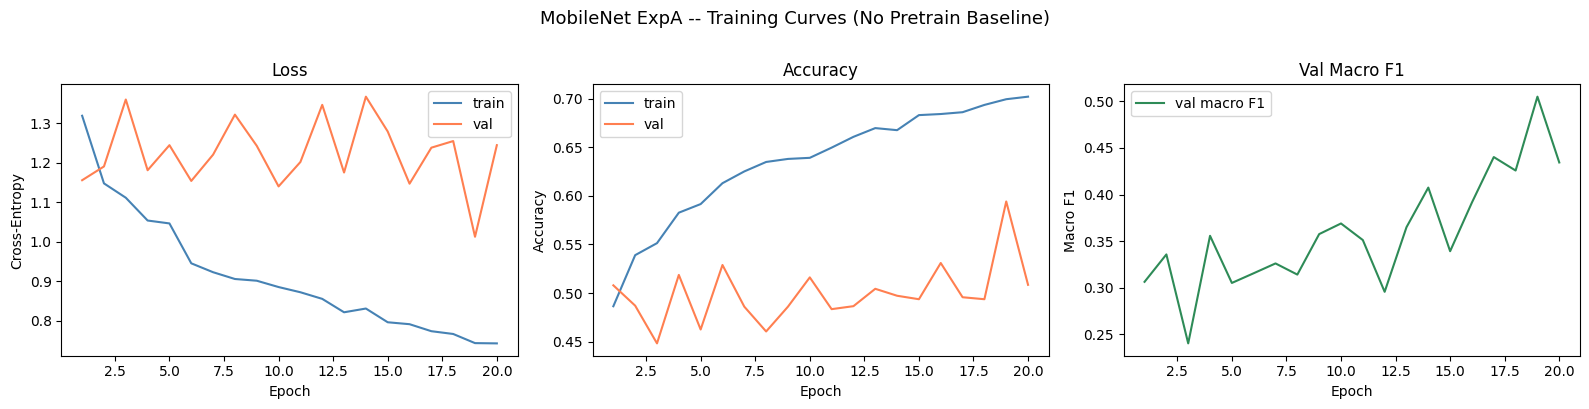


MobileNet ExpA -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.71      0.59      0.65       748
          G3       0.21      0.24      0.22       322
          G4       0.65      0.80      0.72       748
          G5       0.79      0.29      0.43       139

    accuracy                           0.59      1957
   macro avg       0.59      0.48      0.51      1957
weighted avg       0.61      0.59      0.59      1957



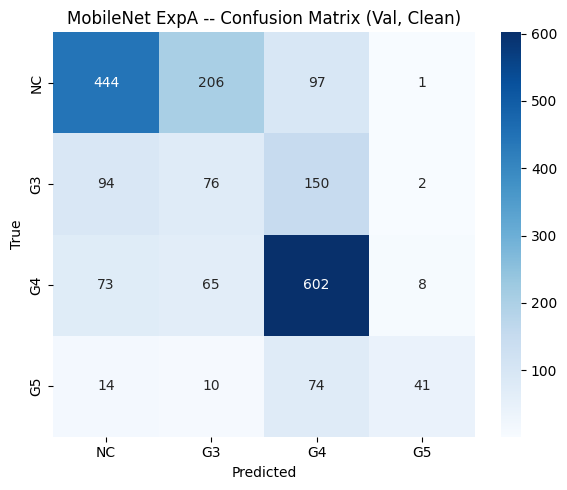

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='mobilenet', key='ExpA',
    config=EXPERIMENT_CONFIGS['ExpA'])

entry = registry_load()['mobilenet']['ExpA']
plot_training_curves(entry['history'],
    title='MobileNet ExpA -- Training Curves (No Pretrain Baseline)',
    warmup_epochs=0)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('mobilenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='MobileNet ExpA -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='MobileNet ExpA -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: MobileNet Exp A

Trained from random weights, MobileNet reaches a val macro F1 of 0.505 and 59% accuracy. The averages hide how uneven the classes are. G4 holds up well (F1 0.72, recall 0.80) and NC is passable at 0.65. G3 falls to 0.22, and G5 is found only 29% of the time (41 of 139 patches), even though the model is usually right when it does predict G5 (precision 0.79).

The confusion matrix shows where the errors go. 206 NC patches are labelled G3, which is why G3 precision sits at 0.21, and another 150 true G3 patches are pushed into G4. Most missed G5 patches (74) also end up in G4. Under a uniform loss, a class with 139 validation patches has little pull on the model, so it defaults to the large neighbouring class.

The curves show a model that is still learning rather than one that has overfit. Training accuracy only reaches 0.70 by epoch 20, validation loss bounces between roughly 1.0 and 1.37 with no clear trend, and the best F1 arrives at epoch 19, so the 20-epoch budget ran out before training settled. Learning edges, textures and gland shapes from SICAPv2 alone is slow. If that is the bottleneck, ImageNet weights should help most, so Exp B changes only that and keeps everything else switched off.

## MobileNet -- Exp B: Pretrained Only


  ARCH=MOBILENET  KEY=ExpB  REGIME=clean  SEED=42
  Pretrained only -- ImageNet weights, no regularisation


model.safetensors: reconstructing file:   0%|          |  0.00B / 10.2MB            

model.safetensors: downloading bytes:           |  0.00B            

  Loss: uniform CrossEntropy

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=1.6413  val_loss=1.2429  val_acc=0.5641  val_f1=0.4987
    ep  2/2  train_loss=0.7666  val_loss=1.2169  val_acc=0.5708  val_f1=0.5256

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.5545  val_loss=0.9911  val_acc=0.6438  val_f1=0.5622  star new best
    ep  4/22  train_loss=0.3885  val_loss=0.8971  val_acc=0.6852  val_f1=0.6310  star new best
    ep  5/22  train_loss=0.3488  val_loss=1.3479  val_acc=0.5984  val_f1=0.5450  (no improv 1/5)
    ep  6/22  train_loss=0.2592  val_loss=1.1095  val_acc=0.6413  val_f1=0.5833  (no improv 2/5)
    ep  7/22  train_loss=0.2258  val_loss=1.2022  val_acc=0.6014  val_f1=0.5606  (no improv 3/5)
    ep  8/22  train_loss=0.2334  val_loss=1.0295  val_acc=0.7036  val_f1=0.6416  star new best
    ep  9/22  train_loss=0.1493  val_loss=0.9664  val_acc=0.7241  val_f1=0.6571  star new best
    ep 10/22  train_loss=0.1214  val_

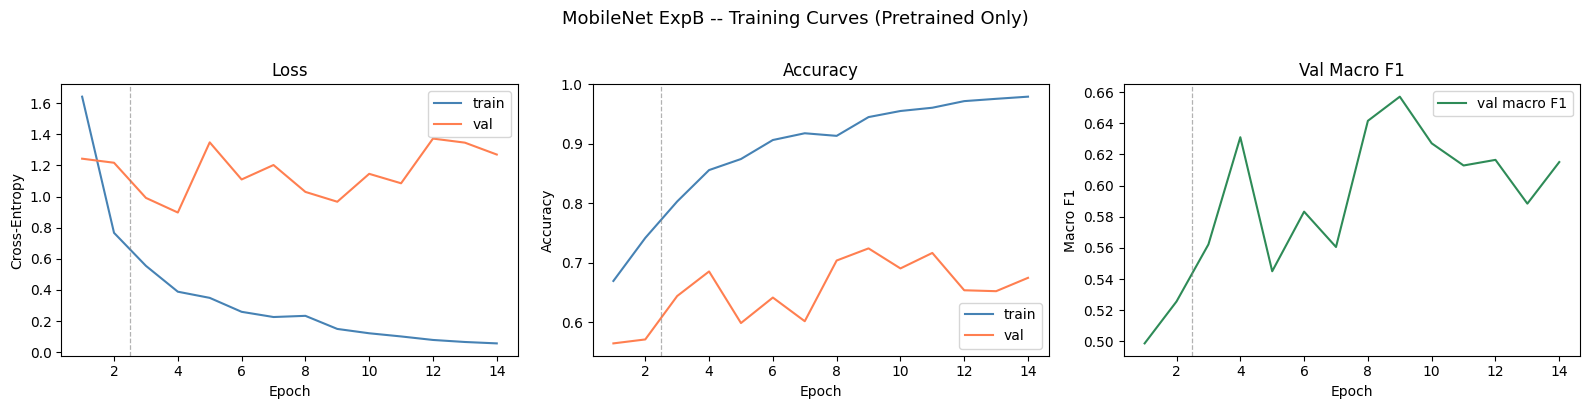


MobileNet ExpB -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.92      0.76      0.83       748
          G3       0.49      0.49      0.49       322
          G4       0.69      0.83      0.75       748
          G5       0.62      0.50      0.56       139

    accuracy                           0.72      1957
   macro avg       0.68      0.65      0.66      1957
weighted avg       0.74      0.72      0.73      1957



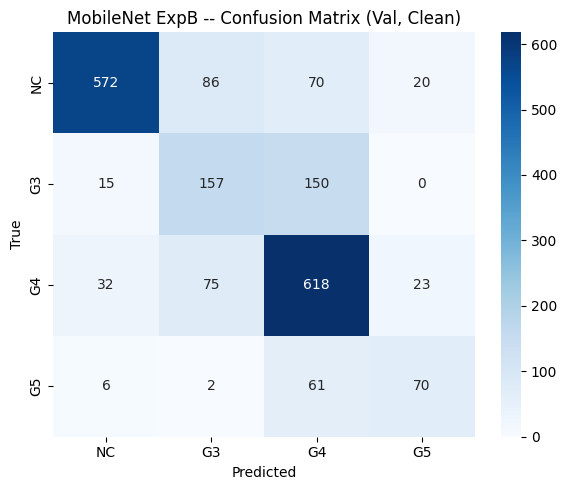

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='mobilenet', key='ExpB',
    config=EXPERIMENT_CONFIGS['ExpB'])

entry = registry_load()['mobilenet']['ExpB']
plot_training_curves(entry['history'],
    title='MobileNet ExpB -- Training Curves (Pretrained Only)',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('mobilenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='MobileNet ExpB -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='MobileNet ExpB -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: MobileNet Exp B

Starting from ImageNet weights lifts val macro F1 from 0.505 to 0.657 and accuracy from 0.59 to 0.72. This is the largest single gain in the MobileNet ablation. Every class improves. NC recall goes from 0.59 to 0.76, the number of NC patches mislabelled as G3 drops from 206 to 86, and G5 recall rises from 0.29 to 0.50.

The training curves tell a different story from Exp A. Training accuracy climbs to about 0.98 and training loss falls close to zero, while validation loss reaches its lowest point around epoch 4 and then drifts upward. The best F1 comes at epoch 9 and early stopping ends the run at epoch 14. The pretrained features let the model fit the training set quickly, and it then starts memorising it.

Two weaknesses remain. G3 and G4 are still confused, with 150 true G3 patches predicted as G4, and 61 G5 patches are still absorbed into G4. Before dealing with the class balance, we first want to see whether the overfitting can be reduced, so Exp C adds weight decay (1e-4) and dropout (0.3) on top of the pretrained model.

## MobileNet -- Exp C: Pretrained + Regularisation


  ARCH=MOBILENET  KEY=ExpC  REGIME=clean  SEED=42
  Pretrained + regularisation (weight_decay=1e-4, drop_rate=0.3)
  Loss: uniform CrossEntropy

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=2.0207  val_loss=1.1138  val_acc=0.6423  val_f1=0.5392
    ep  2/2  train_loss=1.0324  val_loss=1.4890  val_acc=0.5033  val_f1=0.4789

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.6645  val_loss=0.9142  val_acc=0.6811  val_f1=0.6223  star new best
    ep  4/22  train_loss=0.4907  val_loss=0.8439  val_acc=0.7046  val_f1=0.6623  star new best
    ep  5/22  train_loss=0.4403  val_loss=1.2999  val_acc=0.6004  val_f1=0.5097  (no improv 1/5)
    ep  6/22  train_loss=0.3586  val_loss=1.1811  val_acc=0.6648  val_f1=0.5931  (no improv 2/5)
    ep  7/22  train_loss=0.3223  val_loss=0.9808  val_acc=0.6929  val_f1=0.6214  (no improv 3/5)
    ep  8/22  train_loss=0.2992  val_loss=0.9267  val_acc=0.7087  val_f1=0.6281  (no improv 4/5)
    ep  9/22  

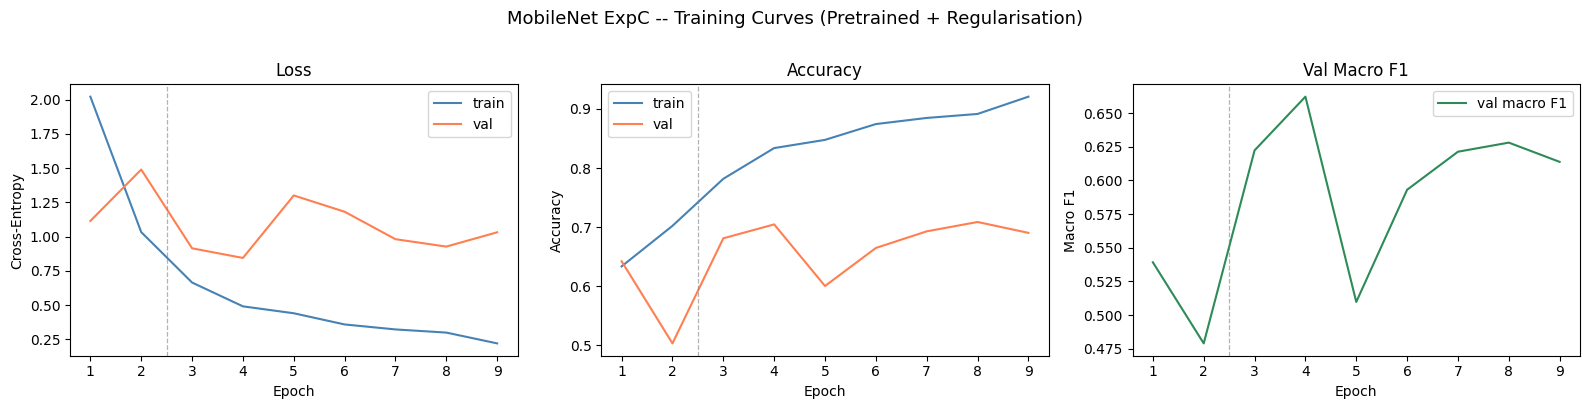


MobileNet ExpC -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.90      0.70      0.79       748
          G3       0.42      0.57      0.48       322
          G4       0.71      0.80      0.75       748
          G5       0.79      0.52      0.63       139

    accuracy                           0.70      1957
   macro avg       0.71      0.65      0.66      1957
weighted avg       0.74      0.70      0.71      1957



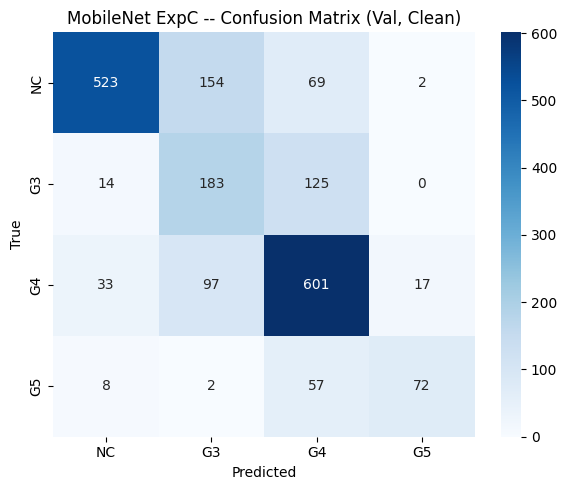

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='mobilenet', key='ExpC',
    config=EXPERIMENT_CONFIGS['ExpC'])

entry = registry_load()['mobilenet']['ExpC']
plot_training_curves(entry['history'],
    title='MobileNet ExpC -- Training Curves (Pretrained + Regularisation)',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('mobilenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='MobileNet ExpC -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='MobileNet ExpC -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: MobileNet Exp C

Regularisation moves val macro F1 from 0.657 to 0.662, a change small enough that a different seed could reverse it. The run is also shorter. Validation F1 peaks at epoch 4 and early stopping ends training at epoch 9. Training accuracy climbs a little more slowly than in Exp B (about 0.92 at epoch 9 against about 0.95), so the regularisers do slow memorisation, but validation loss stays just as noisy.

The per-class picture shifts more than the headline number. G3 recall improves from 0.49 to 0.57 (183 correct against 157), but the model now sends 154 NC patches to G3, up from 86, and NC recall falls from 0.76 to 0.70. G5 barely moves: 72 of 139 are found and 57 are still predicted as G4. Regularisation has moved errors between classes rather than removing them.

What stands out across Exp A to C is that the minority classes, G5 in particular, keep losing to G4. That points to class imbalance more than overfitting. Exp D tests this directly by dropping the regularisers and weighting the loss by inverse class frequency, which gives G5 a weight of 2.26 against 0.43 for NC.

## MobileNet -- Exp D: Pretrained + Class-Weighted Loss


  ARCH=MOBILENET  KEY=ExpD  REGIME=clean  SEED=42
  Pretrained + class-weighted loss
  Loss: class-weighted  weights=[0.43  0.864 0.45  2.256]

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=1.7744  val_loss=1.4495  val_acc=0.5069  val_f1=0.4764
    ep  2/2  train_loss=0.9104  val_loss=1.4908  val_acc=0.5074  val_f1=0.4793

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.6315  val_loss=1.2247  val_acc=0.5953  val_f1=0.5078  star new best
    ep  4/22  train_loss=0.4804  val_loss=1.0696  val_acc=0.6096  val_f1=0.5757  star new best
    ep  5/22  train_loss=0.4074  val_loss=1.5204  val_acc=0.5401  val_f1=0.5353  (no improv 1/5)
    ep  6/22  train_loss=0.2937  val_loss=0.9101  val_acc=0.7297  val_f1=0.6568  star new best
    ep  7/22  train_loss=0.2556  val_loss=1.2494  val_acc=0.6811  val_f1=0.6308  (no improv 1/5)
    ep  8/22  train_loss=0.2545  val_loss=1.5235  val_acc=0.6091  val_f1=0.5467  (no improv 2/5)
    ep  9/22  tra

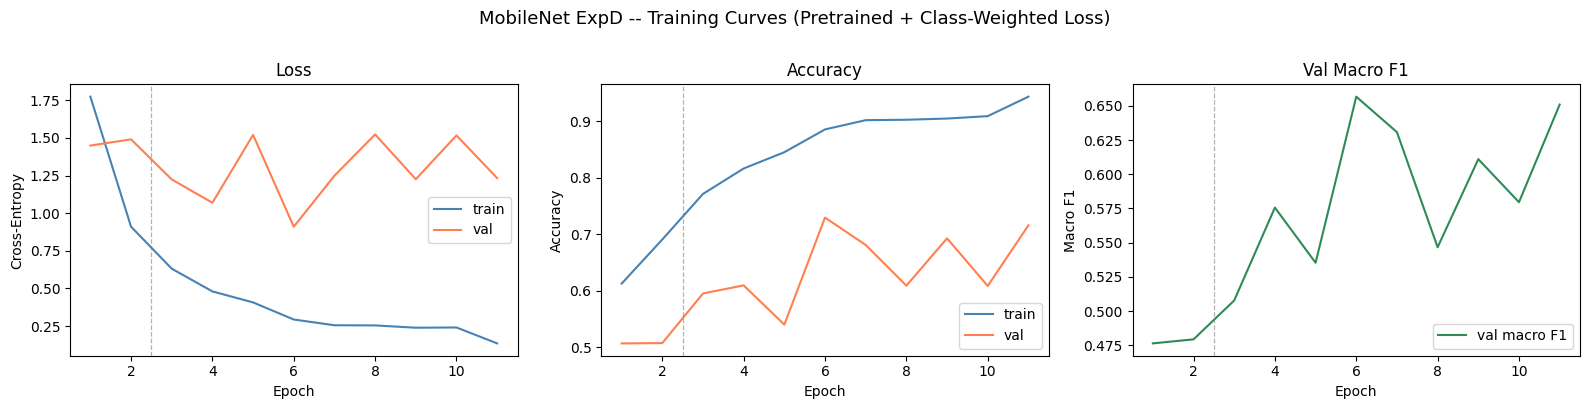


MobileNet ExpD -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.92      0.84      0.88       748
          G3       0.53      0.59      0.56       322
          G4       0.75      0.71      0.73       748
          G5       0.38      0.58      0.46       139

    accuracy                           0.73      1957
   macro avg       0.65      0.68      0.66      1957
weighted avg       0.75      0.73      0.74      1957



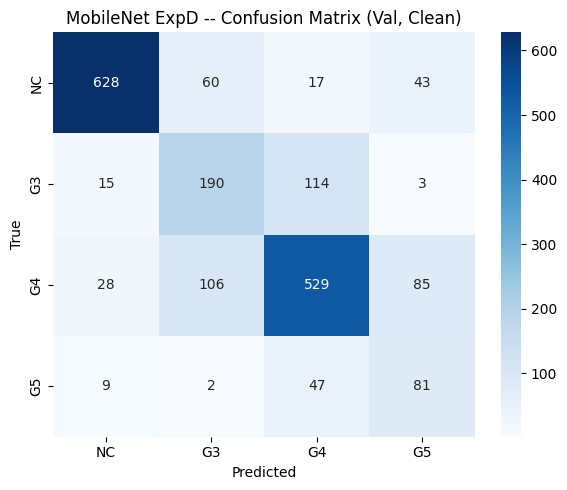

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='mobilenet', key='ExpD',
    config=EXPERIMENT_CONFIGS['ExpD'])

entry = registry_load()['mobilenet']['ExpD']
plot_training_curves(entry['history'],
    title='MobileNet ExpD -- Training Curves (Pretrained + Class-Weighted Loss)',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('mobilenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='MobileNet ExpD -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='MobileNet ExpD -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: MobileNet Exp D

Class weighting leaves val macro F1 almost exactly where Exp B left it (0.657 against 0.657), but the errors are spread very differently. G5 recall rises to 0.58 (81 of 139) and NC recall reaches 0.84, the best so far. G3 also improves, to an F1 of 0.56.

The cost lands on precision for G5. The weighted loss makes G5 errors expensive, so the model now predicts G5 more freely: 85 G4 patches and 43 NC patches are labelled G5, and G5 precision drops from 0.62 in Exp B to 0.38. G4 recall falls from 0.83 to 0.71 for the same reason. The training curves are also the noisiest of the pretrained runs, with validation loss swinging between about 0.9 and 1.5 from one epoch to the next.

So C and D each fix something different. Regularisation slows memorisation a little, and class weighting forces the model to look for the rare grades. Neither improves macro F1 on its own, which raises the question of whether they work better together. Exp E combines both.

## MobileNet -- Exp E: Full Config (Pretrained + Reg + Class Weights)


  ARCH=MOBILENET  KEY=ExpE  REGIME=clean  SEED=42
  Pretrained + regularisation + class-weighted loss (full config)
  Loss: class-weighted  weights=[0.43  0.864 0.45  2.256]

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=2.3243  val_loss=1.3947  val_acc=0.5626  val_f1=0.5161
    ep  2/2  train_loss=1.2036  val_loss=1.6204  val_acc=0.5064  val_f1=0.4922

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.8255  val_loss=1.0284  val_acc=0.6459  val_f1=0.5910  star new best
    ep  4/22  train_loss=0.5792  val_loss=1.4262  val_acc=0.6030  val_f1=0.5512  (no improv 1/5)
    ep  5/22  train_loss=0.5296  val_loss=0.9295  val_acc=0.6771  val_f1=0.6362  star new best
    ep  6/22  train_loss=0.4078  val_loss=1.2177  val_acc=0.6837  val_f1=0.6075  (no improv 1/5)
    ep  7/22  train_loss=0.3859  val_loss=1.1235  val_acc=0.6750  val_f1=0.6363  star new best
    ep  8/22  train_loss=0.3557  val_loss=1.3965  val_acc=0.6270  val_f1=0.5499  (n

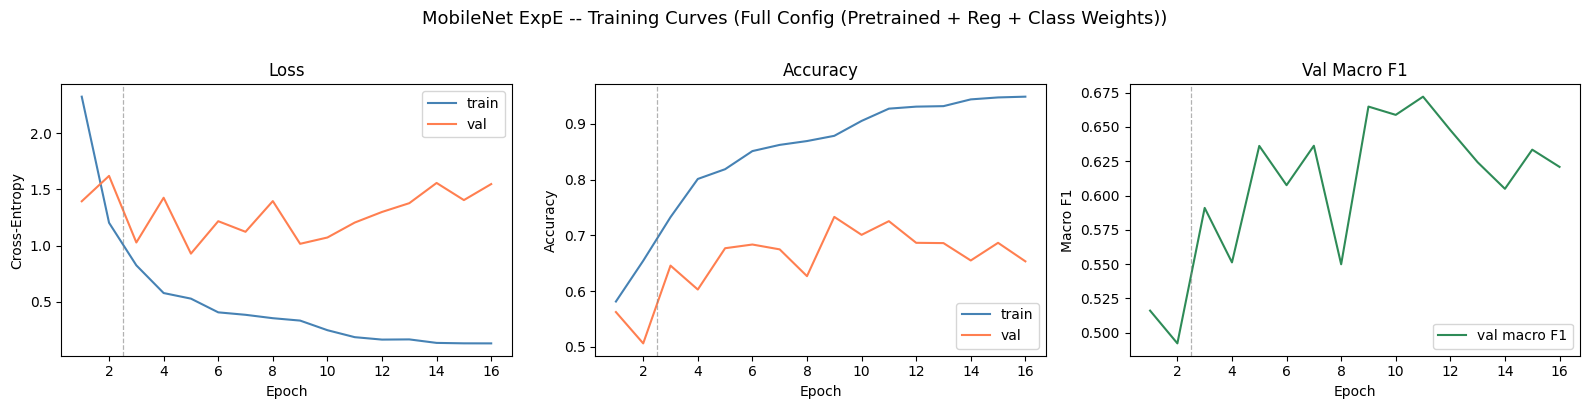


MobileNet ExpE -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.93      0.78      0.85       748
          G3       0.45      0.59      0.51       322
          G4       0.71      0.77      0.74       748
          G5       0.71      0.50      0.59       139

    accuracy                           0.73      1957
   macro avg       0.70      0.66      0.67      1957
weighted avg       0.75      0.73      0.73      1957



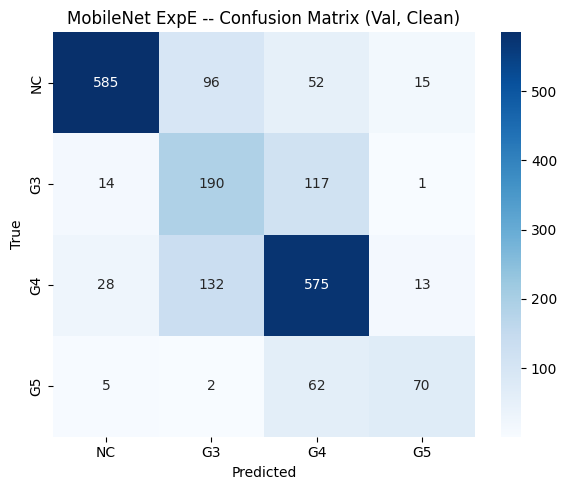

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='mobilenet', key='ExpE',
    config=EXPERIMENT_CONFIGS['ExpE'])

entry = registry_load()['mobilenet']['ExpE']
plot_training_curves(entry['history'],
    title='MobileNet ExpE -- Training Curves (Full Config (Pretrained + Reg + Class Weights))',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('mobilenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='MobileNet ExpE -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='MobileNet ExpE -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: MobileNet Exp E

Combining pretraining, regularisation and class weighting gives the best MobileNet result: val macro F1 of 0.672 and accuracy of 0.73. The gain over Exp B is 0.015, which is modest for a single seed, but this run does avoid the worst side effects seen in C and D. G5 precision recovers to 0.71 (only 13 G4 patches are now predicted as G5, against 85 in Exp D), while G5 recall stays at 0.50. NC keeps a high precision of 0.93.

The curves show the model is still overfitting. Training accuracy reaches about 0.95, and validation loss rises from about 1.0 around epoch 9 to about 1.55 by epoch 16. The best F1 arrives at epoch 11.

The largest error left is now between G3 and G4: 117 true G3 patches are predicted as G4 and 132 G4 patches as G3. Telling these two grades apart depends on fine gland architecture, and one explanation is that a single linear layer on top of the pooled features is too simple to separate them. Exp F tests this by adding a hidden dense layer (1024 to 256, ReLU, dropout, then 4) to the head and keeping the rest of the Exp E config.

## MobileNet -- Exp F: Full Config + Hidden Dense Layer


  ARCH=MOBILENET  KEY=ExpF  REGIME=clean  SEED=42
  Full config + dense projection head (576 → 256 → ReLU → dropout → 4)
  Loss: class-weighted  weights=[0.43  0.864 0.45  2.256]

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=0.8363  val_loss=0.9128  val_acc=0.6520  val_f1=0.5759
    ep  2/2  train_loss=0.7006  val_loss=0.9426  val_acc=0.6270  val_f1=0.5537

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.4972  val_loss=0.8371  val_acc=0.7297  val_f1=0.6464  star new best
    ep  4/22  train_loss=0.3972  val_loss=0.9155  val_acc=0.6975  val_f1=0.6068  (no improv 1/5)
    ep  5/22  train_loss=0.3491  val_loss=1.1788  val_acc=0.6229  val_f1=0.5795  (no improv 2/5)
    ep  6/22  train_loss=0.2903  val_loss=0.8767  val_acc=0.7236  val_f1=0.6606  star new best
    ep  7/22  train_loss=0.2554  val_loss=1.3241  val_acc=0.6530  val_f1=0.6048  (no improv 1/5)
    ep  8/22  train_loss=0.1934  val_loss=1.0461  val_acc=0.7230  val_f1=0.6

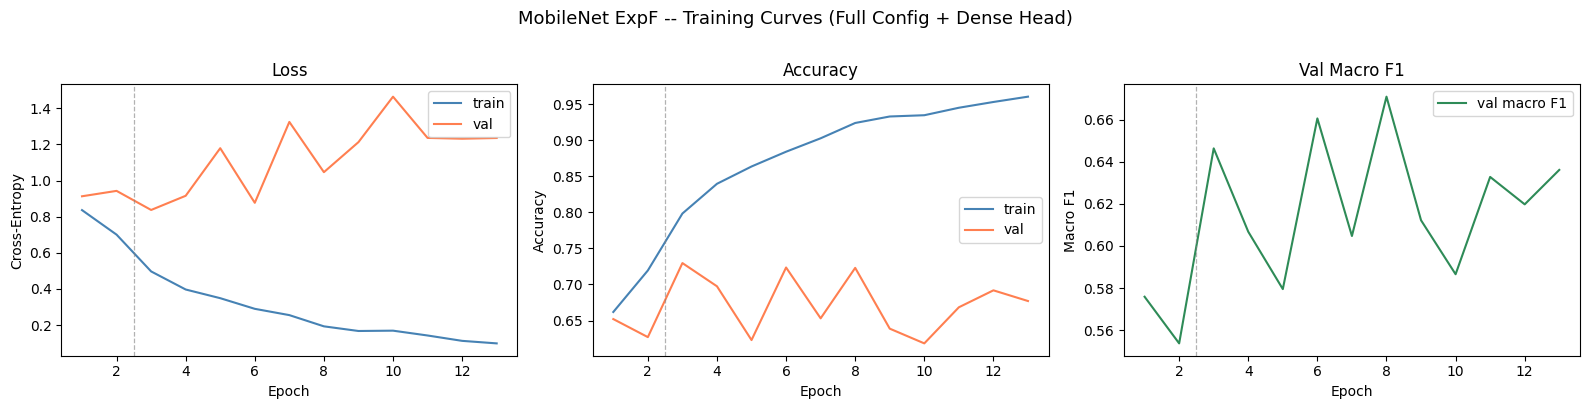


MobileNet ExpF -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.92      0.78      0.85       748
          G3       0.46      0.57      0.51       322
          G4       0.72      0.75      0.73       748
          G5       0.60      0.58      0.59       139

    accuracy                           0.72      1957
   macro avg       0.67      0.67      0.67      1957
weighted avg       0.74      0.72      0.73      1957



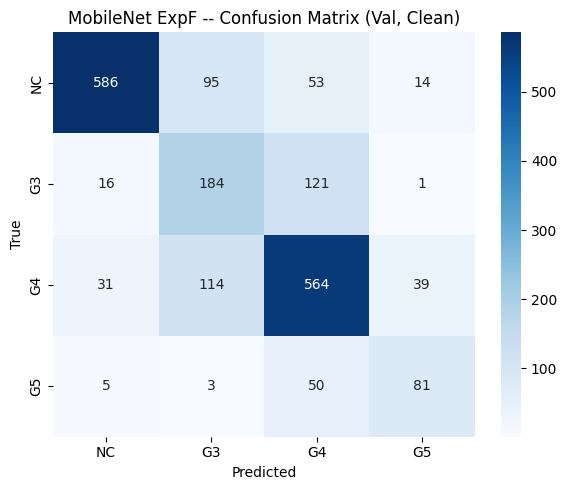

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='mobilenet', key='ExpF',
    config=EXPERIMENT_CONFIGS['ExpF'])

entry = registry_load()['mobilenet']['ExpF']
plot_training_curves(entry['history'],
    title='MobileNet ExpF -- Training Curves (Full Config + Dense Head)',
    warmup_epochs=WARMUP_EPOCHS)

model_eval = build_model_empirical('mobilenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='MobileNet ExpF -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='MobileNet ExpF -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: MobileNet Exp F

The dense head does not help. Val macro F1 is 0.671, essentially the same as Exp E's 0.672. G5 recall improves slightly to 0.58, but more G4 patches are now called G5 (39 against 13), so the G5 F1 is unchanged at 0.59.

The G3 and G4 confusion we were targeting barely moves: 121 G3 patches go to G4 and 114 G4 patches go to G3, against 117 and 132 in Exp E. Validation loss climbs from about 0.84 at epoch 3 to about 1.46 at epoch 10, and early stopping ends the run at epoch 13 with the best F1 at epoch 8. The roughly 260,000 extra head parameters mostly add capacity to memorise.

This suggests the limit is not the classifier head. Either the backbone features do not separate G3 from G4 well at this patch size, or the labels themselves are noisy at that boundary. G3 against G4 is also a common point of disagreement between pathologists, so some of this error may not be learnable from SICAPv2 labels alone. The summary below compares all six runs.

## MobileNet Ablation Summary

Collect all MobileNet ablation results from the registry, display a summary table,
and auto-select the config with the highest val macro F1 to carry forward.

MobileNet Ablation Results:
      Pretrained  WeightDecay  Dropout  ClassWeights  Val Macro F1
Exp                                                               
ExpA       False       0.0000      0.0         False        0.5051
ExpB        True       0.0000      0.0         False        0.6571
ExpC        True       0.0001      0.3         False        0.6623
ExpD        True       0.0000      0.0          True        0.6568
ExpE        True       0.0001      0.3          True        0.6721
ExpF        True       0.0001      0.3          True        0.6709

Best config: ExpE -- val F1 = 0.6721


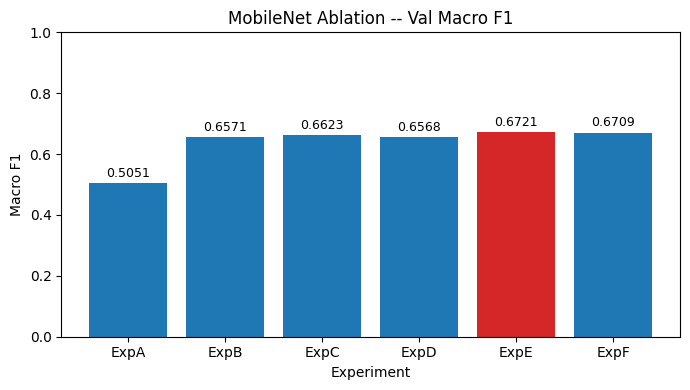

In [ ]:
reg      = registry_load()
ablation = {k: v for k, v in reg.get('mobilenet', {}).items()
            if k in EXPERIMENT_CONFIGS}

rows = []
for name in sorted(ablation):
    e, cfg = ablation[name], ablation[name]['config']
    rows.append({
        'Exp': name,
        'Pretrained'   : cfg.get('pretrained', False),
        'WeightDecay'  : cfg.get('weight_decay', 0.0),
        'Dropout'      : cfg.get('drop_rate', 0.0),
        'ClassWeights' : cfg.get('use_class_weights', False),
        'Val Macro F1' : round(e['val_f1'], 4),
    })

summary_df = pd.DataFrame(rows).set_index('Exp')
print('MobileNet Ablation Results:')
print(summary_df.to_string())

best_name, best_entry = registry_get_best_clean('mobilenet')
print(f'\nBest config: {best_name} -- val F1 = {best_entry["val_f1"]:.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#d62728' if n == best_name else '#1f77b4' for n in summary_df.index]
ax.bar(summary_df.index, summary_df['Val Macro F1'], color=colors)
ax.set_ylim(0, 1); ax.set_title('MobileNet Ablation -- Val Macro F1')
ax.set_xlabel('Experiment'); ax.set_ylabel('Macro F1')
for i, v in enumerate(summary_df['Val Macro F1']):
    ax.text(i, v + 0.01, f'{v:.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

### Analysis: MobileNet ablation summary

The ablation gives a clear message. Pretraining is the only change that makes a large difference: it moves val macro F1 from 0.505 to 0.657. Every config after that lands between 0.657 and 0.672, a spread of 0.015. With a single seed per experiment, differences that small could change order if the experiments were re-run, so we read Exp B to Exp F as roughly equivalent on clean data rather than as a strict ranking.

Where the configs do differ is in how they trade errors between classes. Class weighting raises G5 recall at the expense of G5 precision, regularisation shifts errors between NC and G3, and none of them fixes the G3 and G4 confusion.

The selection rule picks the highest F1, which is Exp E (0.672). It is also a reasonable choice on its own terms, since it has the most balanced G5 precision and recall of the runs. Exp E is carried forward into degradation training in Part 2.

---
# Part 2 -- MobileNet Degradation Training

The best clean-ablation config (selected automatically from the registry) is retrained
with random degradation augmentation so the model learns to classify across image-quality
levels, not only clean slides. Each training batch samples one of the 9 conditions at random.

Using MobileNet best config: ExpE  F1=0.6721

  ARCH=MOBILENET  KEY=degradation  REGIME=degradation  SEED=42
  Pretrained + regularisation + class-weighted loss (full config)
  Loss: class-weighted  weights=[0.43  0.864 0.45  2.256]

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=0.8872  val_loss=0.9515  val_acc=0.6183  val_f1=0.5465
    ep  2/2  train_loss=0.7592  val_loss=0.9297  val_acc=0.6208  val_f1=0.5592

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.5857  val_loss=0.8429  val_acc=0.6704  val_f1=0.6325  star new best
    ep  4/22  train_loss=0.4280  val_loss=0.7881  val_acc=0.7261  val_f1=0.6608  star new best
    ep  5/22  train_loss=0.3892  val_loss=0.7929  val_acc=0.7149  val_f1=0.6653  star new best
    ep  6/22  train_loss=0.3268  val_loss=0.9830  val_acc=0.6745  val_f1=0.6191  (no improv 1/5)
    ep  7/22  train_loss=0.2863  val_loss=1.0657  val_acc=0.6234  val_f1=0.5902  (no improv 2/5)
    ep  8/22  train_loss=

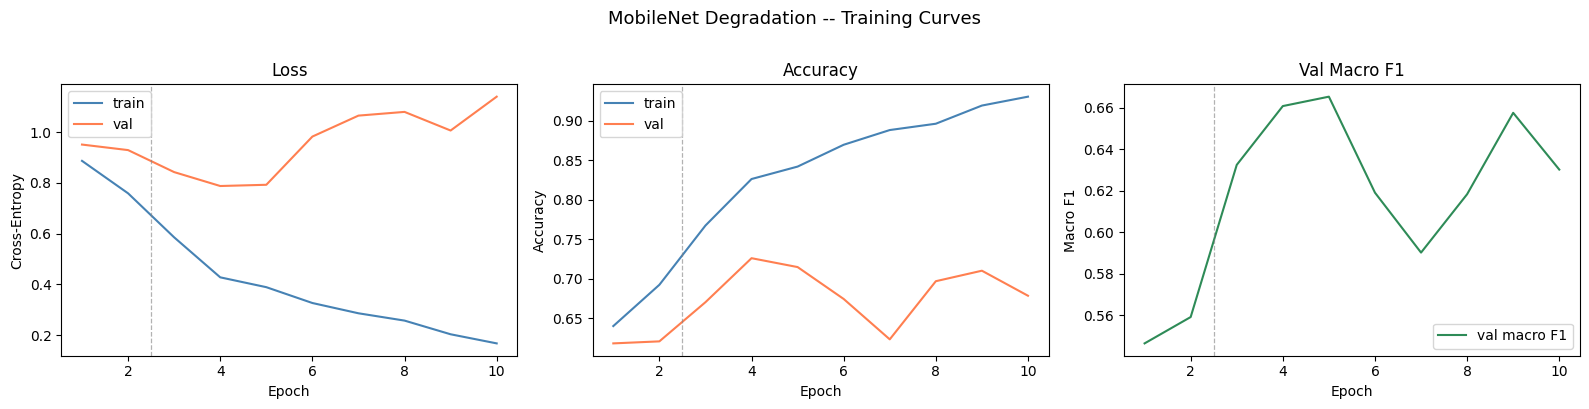


MobileNet Degradation -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.88      0.80      0.84       748
          G3       0.49      0.79      0.60       322
          G4       0.85      0.61      0.71       748
          G5       0.42      0.65      0.51       139

    accuracy                           0.71      1957
   macro avg       0.66      0.71      0.67      1957
weighted avg       0.77      0.71      0.73      1957



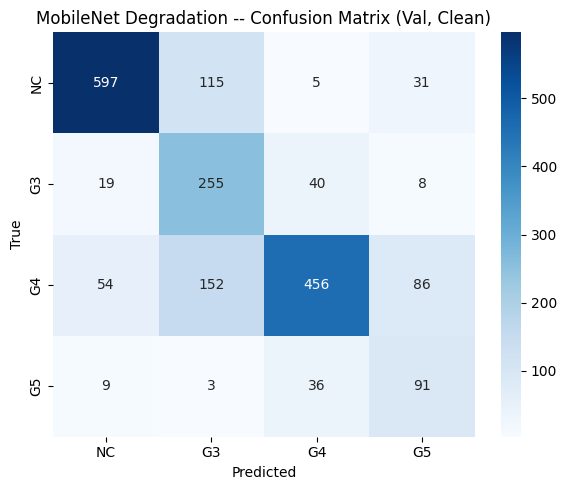

In [ ]:
best_name, best_entry = registry_get_best_clean('mobilenet')
best_cfg_deg = {**best_entry['config'],
               'label': EXPERIMENT_CONFIGS[best_name]['label']}
print(f'Using MobileNet best config: {best_name}  F1={best_entry["val_f1"]:.4f}')

hist, f1, ckpt = run_experiment(
    arch='mobilenet', key='degradation',
    config=best_cfg_deg, regime='degradation')

entry = registry_load()['mobilenet']['degradation']
plot_training_curves(entry['history'],
    title='MobileNet Degradation -- Training Curves',
    warmup_epochs=WARMUP_EPOCHS if entry['config'].get('pretrained', True) else 0)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('mobilenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='MobileNet Degradation -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='MobileNet Degradation -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: MobileNet degradation training

Retrained with random degradation, the Exp E config scores a val macro F1 of 0.665 on clean SICAPv2 patches against 0.672 without augmentation. Training on degraded images costs almost nothing on clean data, which is the first thing we needed to check.

The class behaviour does change. G3 recall jumps from 0.59 to 0.79 (255 of 322), but G4 recall falls from 0.77 to 0.61, with 152 G4 patches now predicted as G3 and 86 as G5. The model has become more willing to call G3. One possible reason is that blur and compression remove the fine detail separating G3 from G4, so during training the model learns to fall back on coarser cues that overlap between the two grades. The curves look like the clean runs: validation F1 peaks at epoch 5, validation loss rises after epoch 5, and early stopping ends the run at epoch 10.

Clean validation data cannot tell us whether this model is more robust. That test happens on the Zurich TMA set in Part 5. Before that, we repeat the same ablation on ShuffleNetV2 to see whether these findings hold for a second architecture.

---
# Part 3 -- ShuffleNetV2-x1.0 Ablation

Six experiments on **clean** SICAPv2 data isolate the contribution of each design choice.
Each experiment varies one ingredient against the pretrained baseline and is evaluated by val macro F1.

| Exp | Pretrained | Weight Decay | Dropout | Class Weights | Dense Head |
|-----|-----------|-------------|---------|---------------|------------|
| A   | No        | --          | --      | --            | --         |
| B   | Yes       | --          | --      | --            | --         |
| C   | Yes       | 1e-4        | 0.3     | --            | --         |
| D   | Yes       | --          | --      | Yes           | --         |
| E   | Yes       | 1e-4        | 0.3     | Yes           | --         |
| F   | Yes       | 1e-4        | 0.3     | Yes           | Yes        |

## ShuffleNet -- Exp A: No Pretrain Baseline


  ARCH=SHUFFLENET  KEY=ExpA  REGIME=clean  SEED=42
  No pretrain -- random init, no regularisation, uniform loss
  Loss: uniform CrossEntropy
  No pretrain -- skipping warmup; training all layers from scratch.

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  1/20  train_loss=1.1016  val_loss=1.0933  val_acc=0.5652  val_f1=0.3431  star new best
    ep  2/20  train_loss=0.9948  val_loss=1.0104  val_acc=0.5989  val_f1=0.3695  star new best
    ep  3/20  train_loss=0.9718  val_loss=0.9252  val_acc=0.6520  val_f1=0.3729  star new best
    ep  4/20  train_loss=0.9291  val_loss=1.0296  val_acc=0.6076  val_f1=0.4414  star new best
    ep  5/20  train_loss=0.8799  val_loss=0.9413  val_acc=0.6454  val_f1=0.4473  star new best
    ep  6/20  train_loss=0.8536  val_loss=0.9800  val_acc=0.6352  val_f1=0.4138  (no improv 1/5)
    ep  7/20  train_loss=0.8178  val_loss=1.0751  val_acc=0.5197  val_f1=0.4049  (no improv 2/5)
    ep  8/20  train_loss=0.7488  val_loss=0.9563  val_acc=

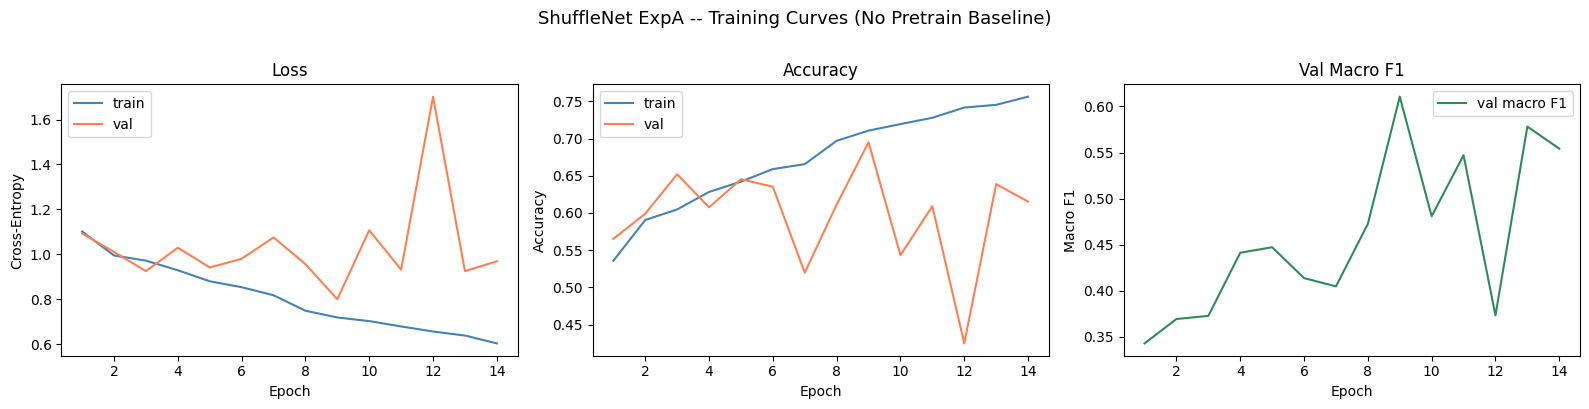


ShuffleNet ExpA -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.78      0.75      0.76       748
          G3       0.42      0.48      0.45       322
          G4       0.74      0.80      0.77       748
          G5       0.75      0.33      0.46       139

    accuracy                           0.69      1957
   macro avg       0.67      0.59      0.61      1957
weighted avg       0.70      0.69      0.69      1957



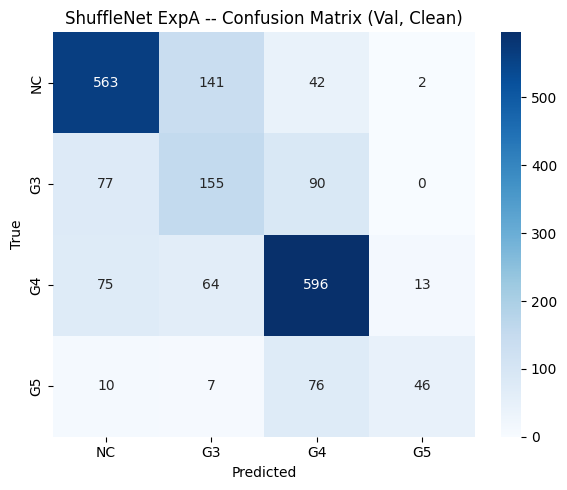

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='shufflenet', key='ExpA',
    config=EXPERIMENT_CONFIGS['ExpA'])

entry = registry_load()['shufflenet']['ExpA']
plot_training_curves(entry['history'],
    title='ShuffleNet ExpA -- Training Curves (No Pretrain Baseline)',
    warmup_epochs=0)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('shufflenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='ShuffleNet ExpA -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='ShuffleNet ExpA -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: ShuffleNet Exp A

Trained from scratch, ShuffleNet reaches a val macro F1 of 0.611, well above MobileNet's 0.505 under the same conditions. NC and G4 both score an F1 of about 0.77. The weak classes are the same as before: G3 reaches 0.45 and G5 0.46, with only 46 of 139 G5 patches found and 76 of them predicted as G4. 141 NC patches are also labelled G3.

Training is unstable. Validation loss jumps to about 1.7 at epoch 12 and validation accuracy swings between about 0.43 and 0.70. The best F1 comes at epoch 9 and early stopping ends the run at epoch 14. We do not have a firm explanation for why ShuffleNet trains better from scratch than MobileNet here. Both are small networks, and with one seed part of the gap could be noise.

The weakness on minority classes and the unstable validation curve match what we saw for MobileNet Exp A. Exp B adds ImageNet weights to test whether pretraining helps ShuffleNet as much as it helped MobileNet.

## ShuffleNet -- Exp B: Pretrained Only


  ARCH=SHUFFLENET  KEY=ExpB  REGIME=clean  SEED=42
  Pretrained only -- ImageNet weights, no regularisation
  Loss: uniform CrossEntropy

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=1.1641  val_loss=1.0923  val_acc=0.6541  val_f1=0.3713
    ep  2/2  train_loss=1.0237  val_loss=1.0145  val_acc=0.6704  val_f1=0.4025

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.6578  val_loss=0.6351  val_acc=0.7517  val_f1=0.6126  star new best
    ep  4/22  train_loss=0.4468  val_loss=0.6053  val_acc=0.7747  val_f1=0.7279  star new best
    ep  5/22  train_loss=0.3757  val_loss=0.5798  val_acc=0.7803  val_f1=0.7213  (no improv 1/5)
    ep  6/22  train_loss=0.3435  val_loss=0.5955  val_acc=0.7813  val_f1=0.7319  star new best
    ep  7/22  train_loss=0.3132  val_loss=0.6106  val_acc=0.7649  val_f1=0.7189  (no improv 1/5)
    ep  8/22  train_loss=0.2844  val_loss=0.6068  val_acc=0.7844  val_f1=0.7324  star new best
    ep  9/22  train_loss=

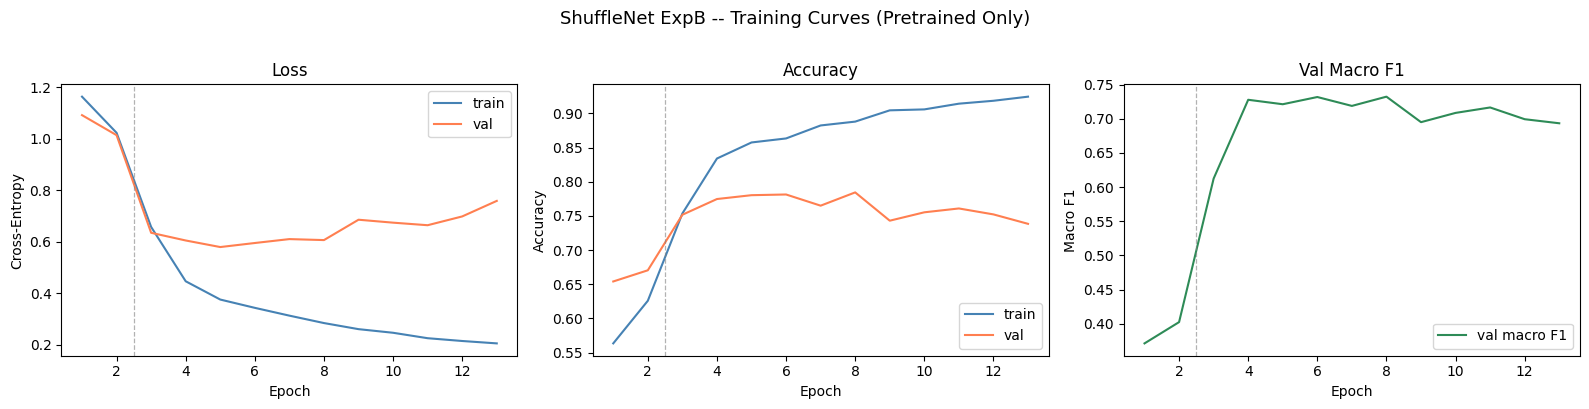


ShuffleNet ExpB -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.88      0.90      0.89       748
          G3       0.65      0.63      0.64       322
          G4       0.78      0.76      0.77       748
          G5       0.61      0.66      0.63       139

    accuracy                           0.78      1957
   macro avg       0.73      0.74      0.73      1957
weighted avg       0.78      0.78      0.78      1957



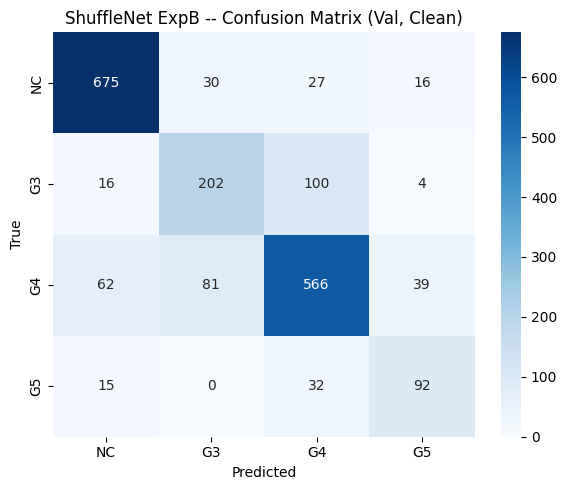

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='shufflenet', key='ExpB',
    config=EXPERIMENT_CONFIGS['ExpB'])

entry = registry_load()['shufflenet']['ExpB']
plot_training_curves(entry['history'],
    title='ShuffleNet ExpB -- Training Curves (Pretrained Only)',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('shufflenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='ShuffleNet ExpB -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='ShuffleNet ExpB -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: ShuffleNet Exp B

Pretraining lifts val macro F1 from 0.611 to 0.732 and accuracy from 0.69 to 0.78. This is the strongest clean result in the notebook so far, and the per-class scores are the most even we have seen: every class F1 falls between 0.63 and 0.89. G5 recall reaches 0.66 (92 of 139) without any class weighting, and only 16 NC patches are mislabelled G5.

The curves are much smoother than in any MobileNet run. Validation F1 reaches about 0.73 by epoch 4 and stays there until around epoch 8. Validation loss reaches its lowest point near epoch 5 and then rises from about 0.58 to 0.76 while training loss keeps falling, which is the familiar sign of overfitting starting. Early stopping ends the run at epoch 13.

The main error is again G3 against G4, with 100 G3 patches predicted as G4 and 81 G4 patches as G3. Given the rising validation loss, the next step mirrors MobileNet: Exp C adds weight decay and dropout.

## ShuffleNet -- Exp C: Pretrained + Regularisation


  ARCH=SHUFFLENET  KEY=ExpC  REGIME=clean  SEED=42
  Pretrained + regularisation (weight_decay=1e-4, drop_rate=0.3)
  Loss: uniform CrossEntropy

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=1.1733  val_loss=1.1047  val_acc=0.6536  val_f1=0.3697
    ep  2/2  train_loss=1.0439  val_loss=1.0324  val_acc=0.6643  val_f1=0.3853

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.6834  val_loss=0.6516  val_acc=0.7450  val_f1=0.5625  star new best
    ep  4/22  train_loss=0.4613  val_loss=0.6119  val_acc=0.7716  val_f1=0.7238  star new best
    ep  5/22  train_loss=0.3854  val_loss=0.5767  val_acc=0.7879  val_f1=0.7289  star new best
    ep  6/22  train_loss=0.3504  val_loss=0.5967  val_acc=0.7798  val_f1=0.7303  star new best
    ep  7/22  train_loss=0.3213  val_loss=0.6000  val_acc=0.7741  val_f1=0.7253  (no improv 1/5)
    ep  8/22  train_loss=0.2926  val_loss=0.6031  val_acc=0.7833  val_f1=0.7316  star new best
    ep  9/22  train

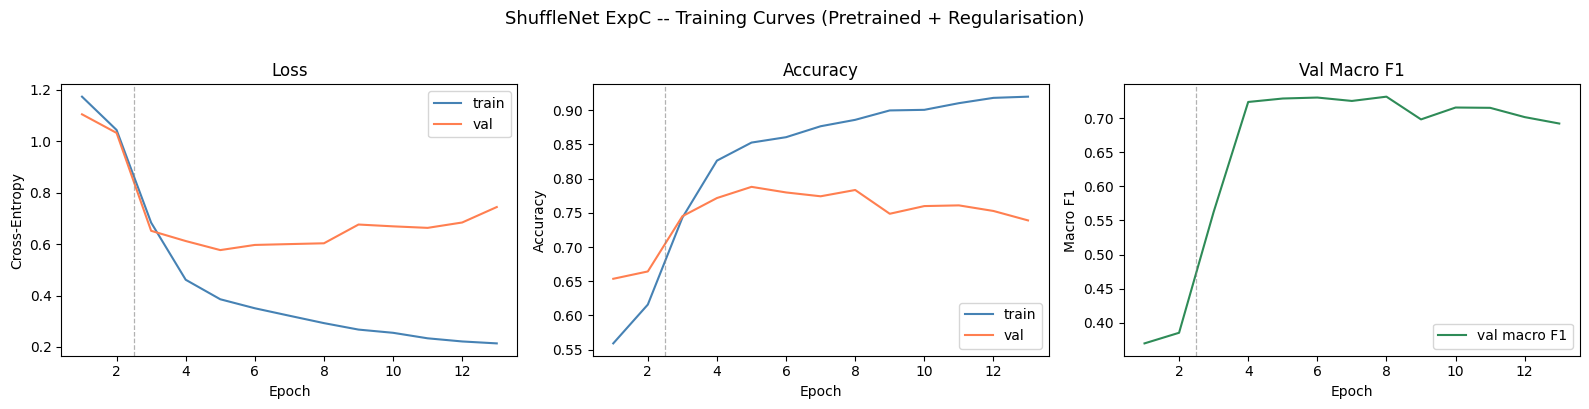


ShuffleNet ExpC -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.88      0.90      0.89       748
          G3       0.64      0.63      0.64       322
          G4       0.78      0.75      0.77       748
          G5       0.60      0.67      0.63       139

    accuracy                           0.78      1957
   macro avg       0.73      0.74      0.73      1957
weighted avg       0.78      0.78      0.78      1957



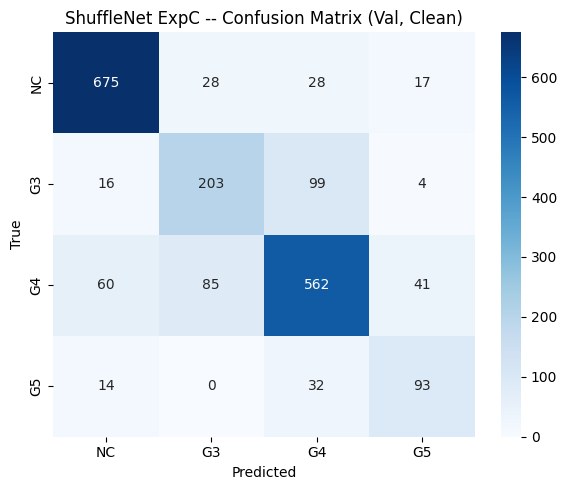

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='shufflenet', key='ExpC',
    config=EXPERIMENT_CONFIGS['ExpC'])

entry = registry_load()['shufflenet']['ExpC']
plot_training_curves(entry['history'],
    title='ShuffleNet ExpC -- Training Curves (Pretrained + Regularisation)',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('shufflenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='ShuffleNet ExpC -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='ShuffleNet ExpC -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: ShuffleNet Exp C

Regularisation has no measurable effect. Val macro F1 is 0.732 against 0.732 for Exp B, and the confusion matrices differ by a few patches per cell. The training curves almost overlay those of Exp B, with the same rise in validation loss after epoch 5 and the same early stop at epoch 13.

The likely reason is that both regularisers are weak in this setup. A weight decay of 1e-4 has little effect over 13 epochs of fine-tuning, and dropout of 0.3 applied only to the final 1024 features touches a small part of the network. With the same seed and data order, the two runs follow nearly the same path.

Since regularisation does not change ShuffleNet's behaviour, the remaining lever from the MobileNet ablation is class weighting. Exp D tests it on its own.

## ShuffleNet -- Exp D: Pretrained + Class-Weighted Loss


  ARCH=SHUFFLENET  KEY=ExpD  REGIME=clean  SEED=42
  Pretrained + class-weighted loss
  Loss: class-weighted  weights=[0.43  0.864 0.45  2.256]

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=1.2922  val_loss=1.2322  val_acc=0.6162  val_f1=0.4945
    ep  2/2  train_loss=1.1475  val_loss=1.1534  val_acc=0.6321  val_f1=0.5359

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.7237  val_loss=0.7554  val_acc=0.7179  val_f1=0.6738  star new best
    ep  4/22  train_loss=0.4953  val_loss=0.7578  val_acc=0.7092  val_f1=0.6680  (no improv 1/5)
    ep  5/22  train_loss=0.4170  val_loss=0.7054  val_acc=0.7573  val_f1=0.7007  star new best
    ep  6/22  train_loss=0.3789  val_loss=0.7212  val_acc=0.7603  val_f1=0.7103  star new best
    ep  7/22  train_loss=0.3475  val_loss=0.7438  val_acc=0.7399  val_f1=0.6993  (no improv 1/5)
    ep  8/22  train_loss=0.3138  val_loss=0.7259  val_acc=0.7435  val_f1=0.6924  (no improv 2/5)
    ep  9/22  tr

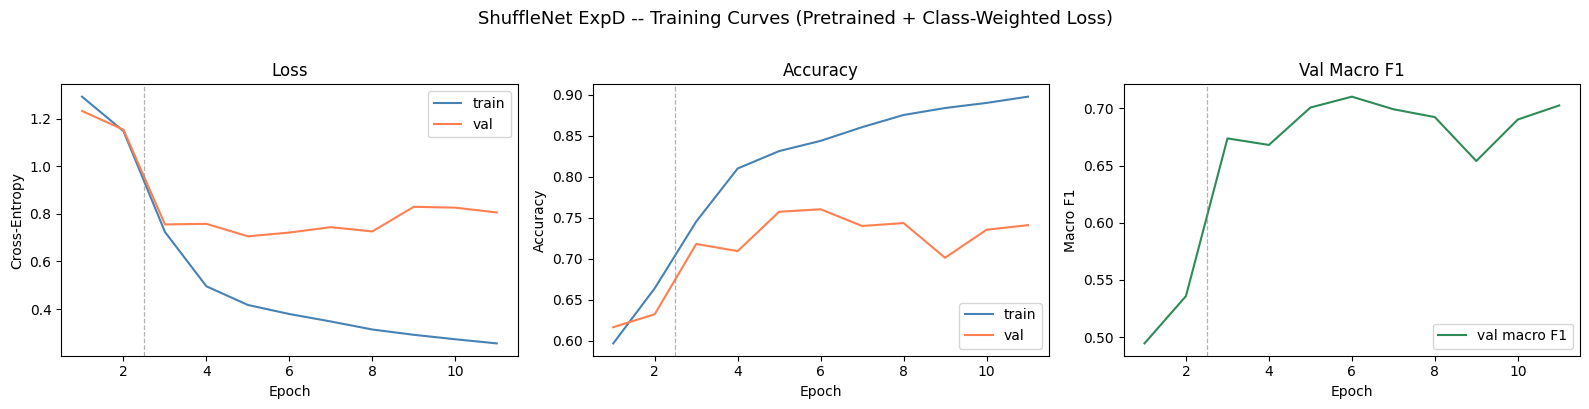


ShuffleNet ExpD -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.91      0.82      0.86       748
          G3       0.62      0.72      0.67       322
          G4       0.79      0.72      0.75       748
          G5       0.46      0.71      0.56       139

    accuracy                           0.76      1957
   macro avg       0.69      0.75      0.71      1957
weighted avg       0.78      0.76      0.77      1957



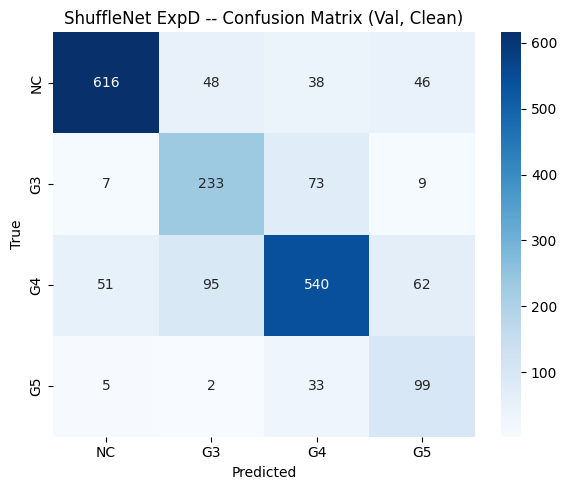

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='shufflenet', key='ExpD',
    config=EXPERIMENT_CONFIGS['ExpD'])

entry = registry_load()['shufflenet']['ExpD']
plot_training_curves(entry['history'],
    title='ShuffleNet ExpD -- Training Curves (Pretrained + Class-Weighted Loss)',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('shufflenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='ShuffleNet ExpD -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='ShuffleNet ExpD -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: ShuffleNet Exp D

Class weighting lowers val macro F1 from 0.732 to 0.710. As with MobileNet, the weighting raises recall on the minority classes: G3 recall goes from 0.63 to 0.72 (233 of 322) and G5 recall from 0.66 to 0.71 (99 of 139). It also produces the same side effect. 62 G4 patches and 46 NC patches are now predicted as G5, G5 precision drops from 0.61 to 0.46, and NC recall falls from 0.90 to 0.82.

The difference from MobileNet is that ShuffleNet Exp B was already fairly balanced, so there was less to gain. The extra minority-class recall is outweighed by the new false positives, and macro F1 goes down. The curves look like Exp B's, with validation loss levelling off around 0.7 to 0.8 after epoch 3.

For MobileNet, combining regularisation with class weighting gave the best result. We run the same combination here as Exp E to check whether that holds for ShuffleNet.

## ShuffleNet -- Exp E: Full Config (Pretrained + Reg + Class Weights)


  ARCH=SHUFFLENET  KEY=ExpE  REGIME=clean  SEED=42
  Pretrained + regularisation + class-weighted loss (full config)
  Loss: class-weighted  weights=[0.43  0.864 0.45  2.256]

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=1.3037  val_loss=1.2460  val_acc=0.6270  val_f1=0.4925
    ep  2/2  train_loss=1.1729  val_loss=1.1742  val_acc=0.6392  val_f1=0.5393

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.7551  val_loss=0.7680  val_acc=0.7128  val_f1=0.6672  star new best
    ep  4/22  train_loss=0.5096  val_loss=0.7568  val_acc=0.7072  val_f1=0.6671  (no improv 1/5)
    ep  5/22  train_loss=0.4279  val_loss=0.7020  val_acc=0.7568  val_f1=0.7008  star new best
    ep  6/22  train_loss=0.3859  val_loss=0.7242  val_acc=0.7629  val_f1=0.7122  star new best
    ep  7/22  train_loss=0.3553  val_loss=0.7342  val_acc=0.7420  val_f1=0.7038  (no improv 1/5)
    ep  8/22  train_loss=0.3232  val_loss=0.7193  val_acc=0.7399  val_f1=0.6874  (

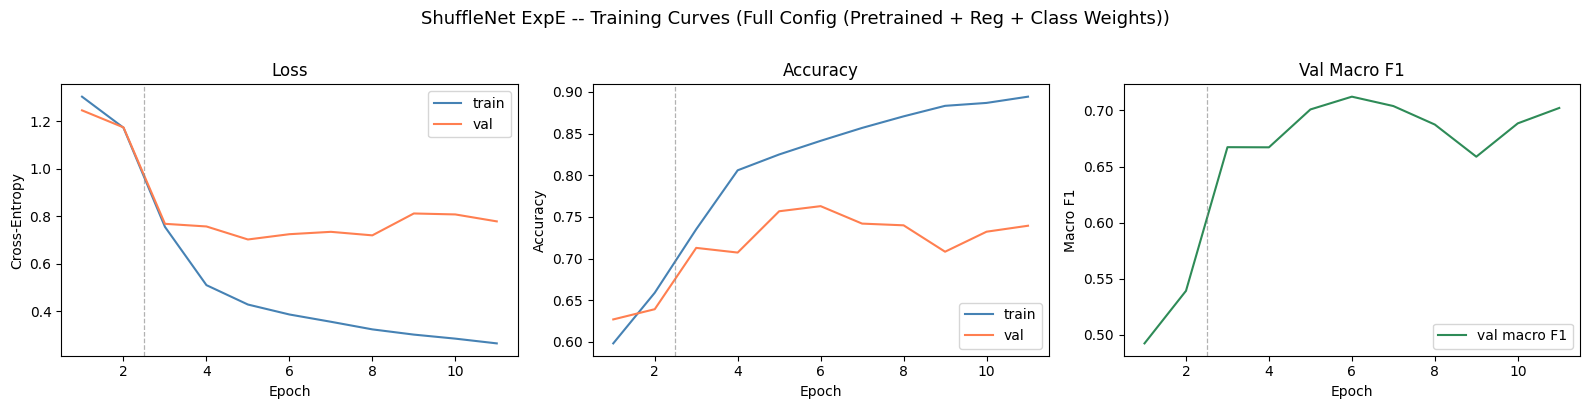


ShuffleNet ExpE -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.91      0.82      0.86       748
          G3       0.62      0.72      0.67       322
          G4       0.80      0.73      0.76       748
          G5       0.45      0.73      0.56       139

    accuracy                           0.76      1957
   macro avg       0.69      0.75      0.71      1957
weighted avg       0.79      0.76      0.77      1957



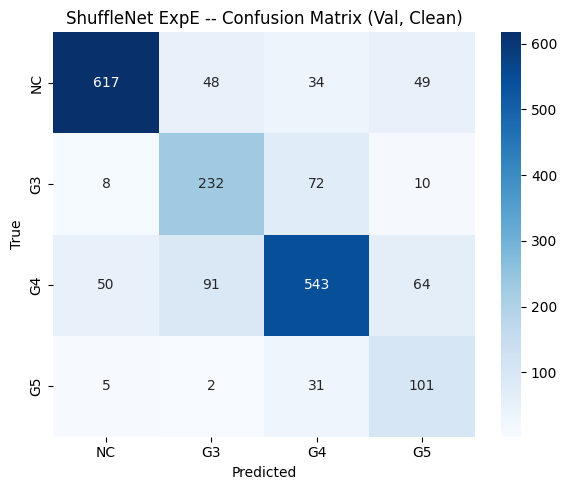

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='shufflenet', key='ExpE',
    config=EXPERIMENT_CONFIGS['ExpE'])

entry = registry_load()['shufflenet']['ExpE']
plot_training_curves(entry['history'],
    title='ShuffleNet ExpE -- Training Curves (Full Config (Pretrained + Reg + Class Weights))',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('shufflenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='ShuffleNet ExpE -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='ShuffleNet ExpE -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: ShuffleNet Exp E

The full config scores 0.712, effectively the same as Exp D's 0.710. The confusion matrices of the two runs differ by only a handful of patches, and the training curves have the same shape. This is consistent with Exp C: on ShuffleNet, weight decay and dropout at these settings change almost nothing, so Exp E behaves like class weighting alone.

The class-level pattern is therefore the same as in Exp D. G5 recall is high at 0.73 (101 of 139), G5 precision is low at 0.45, and 64 G4 patches are predicted as G5. The combination that worked best for MobileNet does not carry over, because here regularisation has nothing to correct and class weighting costs more than it gains.

To finish the ablation in parallel with MobileNet, Exp F adds the hidden dense layer to the head.

## ShuffleNet -- Exp F: Full Config + Hidden Dense Layer


  ARCH=SHUFFLENET  KEY=ExpF  REGIME=clean  SEED=42
  Full config + dense projection head (576 → 256 → ReLU → dropout → 4)
  Loss: class-weighted  weights=[0.43  0.864 0.45  2.256]

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=1.0357  val_loss=0.9586  val_acc=0.6306  val_f1=0.5606
    ep  2/2  train_loss=0.7614  val_loss=0.9441  val_acc=0.5994  val_f1=0.5495

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.6049  val_loss=0.8071  val_acc=0.6755  val_f1=0.6234  star new best
    ep  4/22  train_loss=0.4709  val_loss=0.7532  val_acc=0.7496  val_f1=0.6904  star new best
    ep  5/22  train_loss=0.4081  val_loss=0.8368  val_acc=0.6995  val_f1=0.6508  (no improv 1/5)
    ep  6/22  train_loss=0.3543  val_loss=0.8253  val_acc=0.7195  val_f1=0.6676  (no improv 2/5)
    ep  7/22  train_loss=0.3244  val_loss=0.9022  val_acc=0.6995  val_f1=0.6561  (no improv 3/5)
    ep  8/22  train_loss=0.2962  val_loss=0.8529  val_acc=0.7159  val_f1=0.

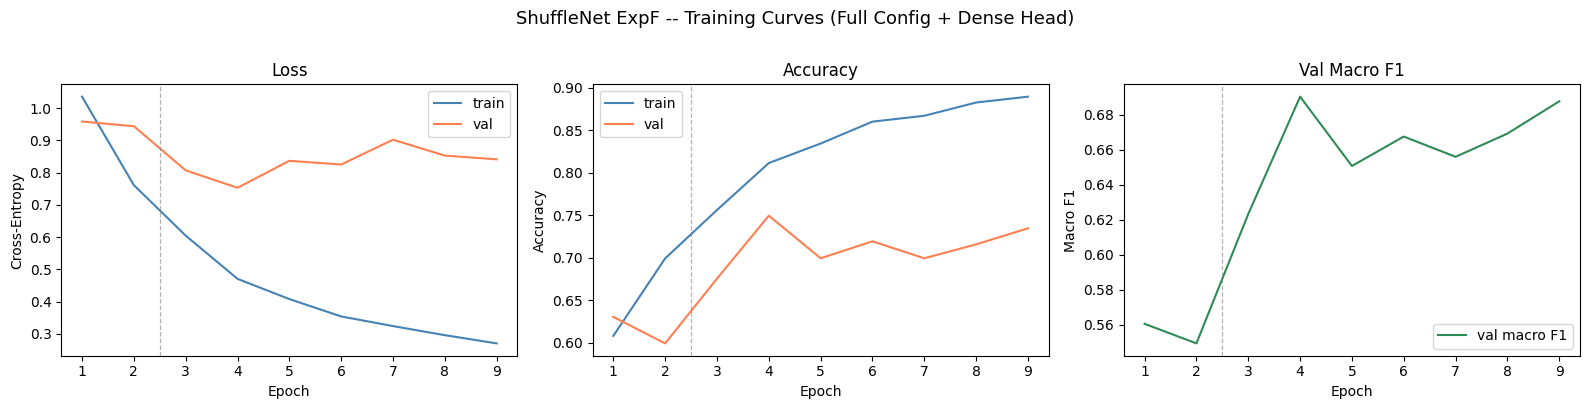


ShuffleNet ExpF -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.87      0.84      0.86       748
          G3       0.62      0.58      0.60       322
          G4       0.77      0.74      0.75       748
          G5       0.45      0.71      0.55       139

    accuracy                           0.75      1957
   macro avg       0.68      0.72      0.69      1957
weighted avg       0.76      0.75      0.75      1957



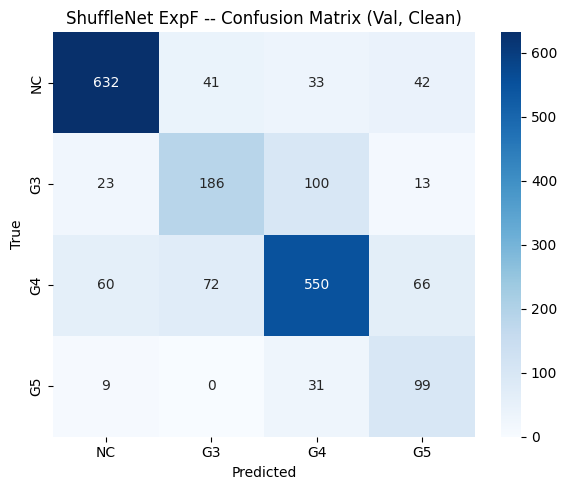

In [ ]:
hist, f1, ckpt = run_experiment(
    arch='shufflenet', key='ExpF',
    config=EXPERIMENT_CONFIGS['ExpF'])

entry = registry_load()['shufflenet']['ExpF']
plot_training_curves(entry['history'],
    title='ShuffleNet ExpF -- Training Curves (Full Config + Dense Head)',
    warmup_epochs=WARMUP_EPOCHS)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('shufflenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='ShuffleNet ExpF -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='ShuffleNet ExpF -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: ShuffleNet Exp F

The dense head gives the lowest pretrained result for ShuffleNet, a val macro F1 of 0.690. Validation F1 peaks at epoch 4, validation loss starts rising from the same epoch, and early stopping ends the run at epoch 9. G3 suffers most: recall falls from 0.72 in Exp E to 0.58, with 100 G3 patches predicted as G4. G5 behaves as in D and E, with high recall (0.71) and low precision (0.45).

The extra head layer starts from random weights on top of a pretrained backbone and brings about 260,000 new parameters. On a dataset of this size, that seems to add overfitting without making the features any more separable, which matches the MobileNet result. Neither architecture benefits from a deeper head.

## ShuffleNet Ablation Summary

Collect all ShuffleNet ablation results from the registry, display a summary table,
and auto-select the config with the highest val macro F1 to carry forward.

ShuffleNet Ablation Results:
      Pretrained  WeightDecay  Dropout  ClassWeights  Val Macro F1
Exp                                                               
ExpA       False       0.0000      0.0         False        0.6106
ExpB        True       0.0000      0.0         False        0.7324
ExpC        True       0.0001      0.3         False        0.7316
ExpD        True       0.0000      0.0          True        0.7103
ExpE        True       0.0001      0.3          True        0.7122
ExpF        True       0.0001      0.3          True        0.6904

Best config: ExpB -- val F1 = 0.7324


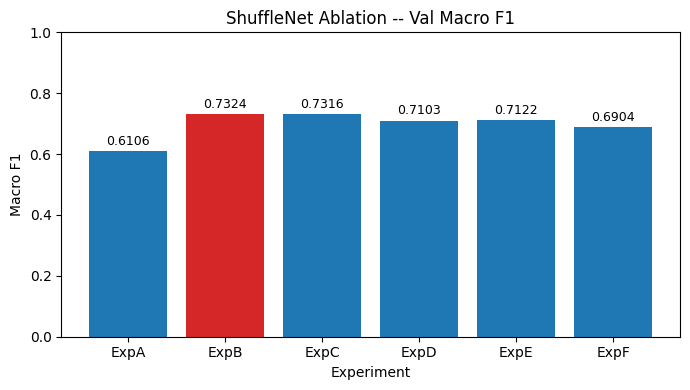

In [ ]:
reg      = registry_load()
ablation = {k: v for k, v in reg.get('shufflenet', {}).items()
            if k in EXPERIMENT_CONFIGS}

rows = []
for name in sorted(ablation):
    e, cfg = ablation[name], ablation[name]['config']
    rows.append({
        'Exp': name,
        'Pretrained'   : cfg.get('pretrained', False),
        'WeightDecay'  : cfg.get('weight_decay', 0.0),
        'Dropout'      : cfg.get('drop_rate', 0.0),
        'ClassWeights' : cfg.get('use_class_weights', False),
        'Val Macro F1' : round(e['val_f1'], 4),
    })

summary_df = pd.DataFrame(rows).set_index('Exp')
print('ShuffleNet Ablation Results:')
print(summary_df.to_string())

best_name, best_entry = registry_get_best_clean('shufflenet')
print(f'\nBest config: {best_name} -- val F1 = {best_entry["val_f1"]:.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#d62728' if n == best_name else '#1f77b4' for n in summary_df.index]
ax.bar(summary_df.index, summary_df['Val Macro F1'], color=colors)
ax.set_ylim(0, 1); ax.set_title('ShuffleNet Ablation -- Val Macro F1')
ax.set_xlabel('Experiment'); ax.set_ylabel('Macro F1')
for i, v in enumerate(summary_df['Val Macro F1']):
    ax.text(i, v + 0.01, f'{v:.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

### Analysis: ShuffleNet ablation summary

The ShuffleNet ablation repeats the main MobileNet finding. Pretraining is the big step, from 0.611 to 0.732, and everything after it falls within 0.04 of that. Unlike MobileNet, the extra ingredients here do not help at all. Regularisation changes nothing, and class weighting and the dense head both lower macro F1 by raising G5 recall at a large cost to G5 precision.

The selection rule picks Exp B (0.732). Exp C is within 0.001, but B is the simpler config, so it is the better one to carry forward. Single-seed caution applies here as well. The gap between B and E is 0.020, larger than in MobileNet but still small enough to treat with care.

The two architectures therefore move into degradation training with different configs. MobileNet uses the full config (Exp E) and ShuffleNet uses pretraining alone (Exp B). Part 4 retrains the ShuffleNet config with random degradation.

---
# Part 4 -- ShuffleNet Degradation Training

The best clean-ablation config (selected automatically from the registry) is retrained
with random degradation augmentation so the model learns to classify across image-quality
levels, not only clean slides. Each training batch samples one of the 9 conditions at random.

Using ShuffleNet best config: ExpB  F1=0.7324

  ARCH=SHUFFLENET  KEY=degradation  REGIME=degradation  SEED=42
  Pretrained only -- ImageNet weights, no regularisation
  Loss: uniform CrossEntropy

  Phase 1 -- warmup (2 epochs, head only)
    ep  1/2  train_loss=1.1731  val_loss=1.1117  val_acc=0.6352  val_f1=0.3582
    ep  2/2  train_loss=1.0438  val_loss=1.0390  val_acc=0.6571  val_f1=0.3942

  Phase 2 -- full fine-tune (up to 20 epochs, ES patience=5)
    ep  3/22  train_loss=0.6943  val_loss=0.6968  val_acc=0.7312  val_f1=0.5994  star new best
    ep  4/22  train_loss=0.4889  val_loss=0.6361  val_acc=0.7655  val_f1=0.7168  star new best
    ep  5/22  train_loss=0.4203  val_loss=0.6159  val_acc=0.7675  val_f1=0.7179  star new best
    ep  6/22  train_loss=0.3863  val_loss=0.5988  val_acc=0.7772  val_f1=0.7240  star new best
    ep  7/22  train_loss=0.3558  val_loss=0.5968  val_acc=0.7803  val_f1=0.7371  star new best
    ep  8/22  train_loss=0.3326  val_loss=0.6092  val_acc=0.7741 

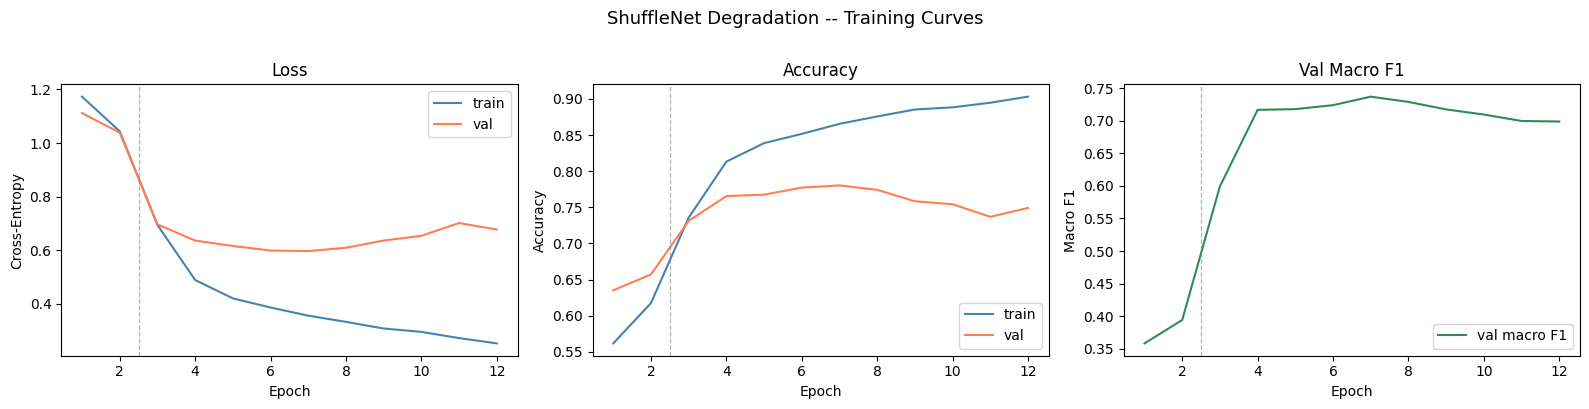


ShuffleNet Degradation -- Classification Report (Val, Clean)
              precision    recall  f1-score   support

          NC       0.88      0.88      0.88       748
          G3       0.58      0.67      0.62       322
          G4       0.79      0.76      0.77       748
          G5       0.72      0.63      0.67       139

    accuracy                           0.78      1957
   macro avg       0.74      0.73      0.74      1957
weighted avg       0.79      0.78      0.78      1957



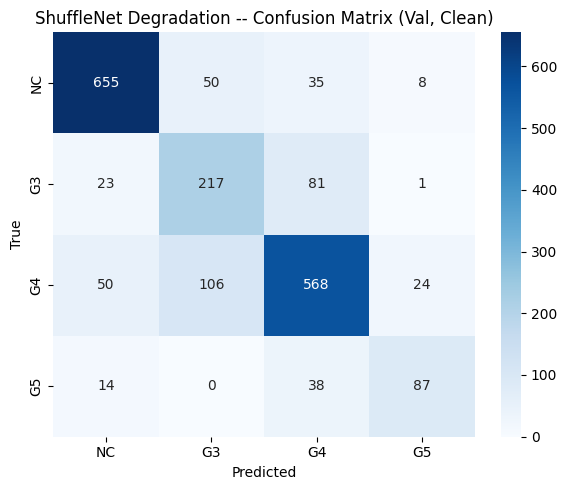

In [58]:
best_name, best_entry = registry_get_best_clean('shufflenet')
best_cfg_deg = {**best_entry['config'],
               'label': EXPERIMENT_CONFIGS[best_name]['label']}
print(f'Using ShuffleNet best config: {best_name}  F1={best_entry["val_f1"]:.4f}')

hist, f1, ckpt = run_experiment(
    arch='shufflenet', key='degradation',
    config=best_cfg_deg, regime='degradation')

entry = registry_load()['shufflenet']['degradation']
plot_training_curves(entry['history'],
    title='ShuffleNet Degradation -- Training Curves',
    warmup_epochs=WARMUP_EPOCHS if entry['config'].get('pretrained', True) else 0)

# === Evaluation on clean val set ===
model_eval = build_model_empirical('shufflenet', entry['config'])
model_eval.load_state_dict(torch.load(entry['ckpt'], map_location=DEVICE))
model_eval.eval()
yt, yp = evaluate_on_condition(model_eval, val_df, SICAP_IMGS, 'clean')
print_cls_report(yt, yp, title='ShuffleNet Degradation -- Classification Report (Val, Clean)')
plot_confusion_matrix(yt, yp, title='ShuffleNet Degradation -- Confusion Matrix (Val, Clean)')
del model_eval
if torch.cuda.is_available(): torch.cuda.empty_cache()

### Analysis: ShuffleNet degradation training

Degradation training does not hurt ShuffleNet on clean data. Val macro F1 is 0.737, slightly above the 0.732 of Exp B, and the curves are as smooth as before: validation F1 peaks at epoch 7, validation loss stays between about 0.6 and 0.7, and early stopping ends the run at epoch 12. G5 is handled well, with a precision of 0.72 and recall of 0.63 (87 of 139). G3 and G4 remain the main confusion, with 106 G4 patches predicted as G3 and 81 G3 patches as G4.

Unlike MobileNet, ShuffleNet's class balance barely changes when degradation is added. The only notable shift is a small move toward predicting G3, the same direction we saw for MobileNet but much weaker.

On clean SICAPv2, all four final models now sit between 0.665 and 0.737, so this data cannot separate the clean-trained from the degradation-trained models. Part 5 evaluates all four on Zurich TMA, a dataset none of them has seen, across every degradation condition.

---
# Part 5 -- Zurich TMA Cross-Dataset Evaluation

All four trained models are evaluated on the fully held-out **Zurich TMA** dataset
across all nine degradation conditions. No Zurich data entered training or
hyperparameter selection.

Models evaluated:
- **MN-Clean**: MobileNet trained on clean data with best ablation config
- **MN-Deg**:   MobileNet trained with degradation-aware augmentation
- **SN-Clean**: ShuffleNet trained on clean data with best ablation config
- **SN-Deg**:   ShuffleNet trained with degradation-aware augmentation

Primary metric: macro F1 per condition.

## Load Zurich Dataset

Read the held-out Zurich TMA manifest. This dataset is never seen during training or
hyperparameter selection. The `eligible` flag marks patches that pass quality control.

Total Zurich rows : 3,055
Eligible patches  : 3,055

Zurich label distribution:
  NC (0): 460
  G3 (1): 1,173
  G4 (2): 1,006
  G5 (3): 416


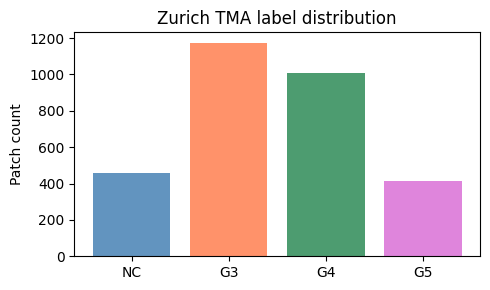

In [59]:
zurich_df = pd.read_csv(ZURICH_CSV)
print(f'Total Zurich rows : {len(zurich_df):,}')

# Keep only quality-controlled patches
if 'eligible' in zurich_df.columns:
    zurich_df = zurich_df[zurich_df['eligible'] == True].reset_index(drop=True)
    print(f'Eligible patches  : {len(zurich_df):,}')

# Labels are integers 0-3 (0=NC, 1=G3, 2=G4, 3=G5)
print('\nZurich label distribution:')
counts = zurich_df['label'].value_counts().sort_index()
for i, v in counts.items():
    print(f'  {CLASS_NAMES[int(i)]} ({i}): {v:,}')

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(CLASS_NAMES, [counts.get(i, 0) for i in range(NUM_CLASSES)],
       color=['steelblue', 'coral', 'seagreen', 'orchid'], alpha=0.85)
ax.set_title('Zurich TMA label distribution')
ax.set_ylabel('Patch count')
plt.tight_layout(); plt.show()

## Load All 4 Checkpoints

Resolve the best clean config for each architecture from the registry,
then load all four checkpoints into memory.

In [67]:
reg = registry_load()

best_mn_key, _ = registry_get_best_clean('mobilenet')
best_sn_key, _ = registry_get_best_clean('shufflenet')

MODELS = {
    'MN-Clean' : load_from_registry('mobilenet',  best_mn_key),
    'MN-Deg'   : load_from_registry('mobilenet',  'degradation'),
    'SN-Clean' : load_from_registry('shufflenet', best_sn_key),
    'SN-Deg'   : load_from_registry('shufflenet', 'degradation'),
}

for name, (model, entry) in MODELS.items():
    print(f'  {name:10s}: {entry["label"]}')

  MN-Clean  : Pretrained + regularisation + class-weighted loss (full config)
  MN-Deg    : Pretrained + regularisation + class-weighted loss (full config)
  SN-Clean  : Pretrained only -- ImageNet weights, no regularisation
  SN-Deg    : Pretrained only -- ImageNet weights, no regularisation


## Cross-Dataset Generalisation Table (Macro F1)

Evaluate every model under every degradation condition.
This is the primary result table of the experiment.

In [68]:
MODEL_NAMES = list(MODELS.keys())
results     = {m: {} for m in MODEL_NAMES}

for mname, (model, _) in MODELS.items():
    print(f'Evaluating {mname} ...')
    for cond in CONDITION_NAMES:
        yt, yp = evaluate_on_condition(model, zurich_df, ZURICH_IMGS, cond)
        f1 = f1_score(yt, yp, labels=list(range(NUM_CLASSES)),
                      average='macro', zero_division=0)
        results[mname][cond] = round(f1, 4)
        print(f'  {cond:<25s}  macro F1={f1:.4f}')

results_df = pd.DataFrame(results, index=CONDITION_NAMES)
print('\n== Zurich Cross-Dataset Generalisation Table (Macro F1) ==')
print(results_df.to_string())

Evaluating MN-Clean ...
  clean                      macro F1=0.3403
  jpeg75                     macro F1=0.3173
  jpeg50                     macro F1=0.3068
  jpeg25                     macro F1=0.2660
  res256                     macro F1=0.2192
  res128                     macro F1=0.1777
  res256_jpeg50              macro F1=0.1968
  res128_jpeg25              macro F1=0.1344
  stress_res64_jpeg25        macro F1=0.1844
Evaluating MN-Deg ...
  clean                      macro F1=0.5775
  jpeg75                     macro F1=0.5776
  jpeg50                     macro F1=0.5810
  jpeg25                     macro F1=0.5699
  res256                     macro F1=0.5064
  res128                     macro F1=0.4537
  res256_jpeg50              macro F1=0.5086
  res128_jpeg25              macro F1=0.4486
  stress_res64_jpeg25        macro F1=0.3191
Evaluating SN-Clean ...
  clean                      macro F1=0.5169
  jpeg75                     macro F1=0.5689
  jpeg50                     m

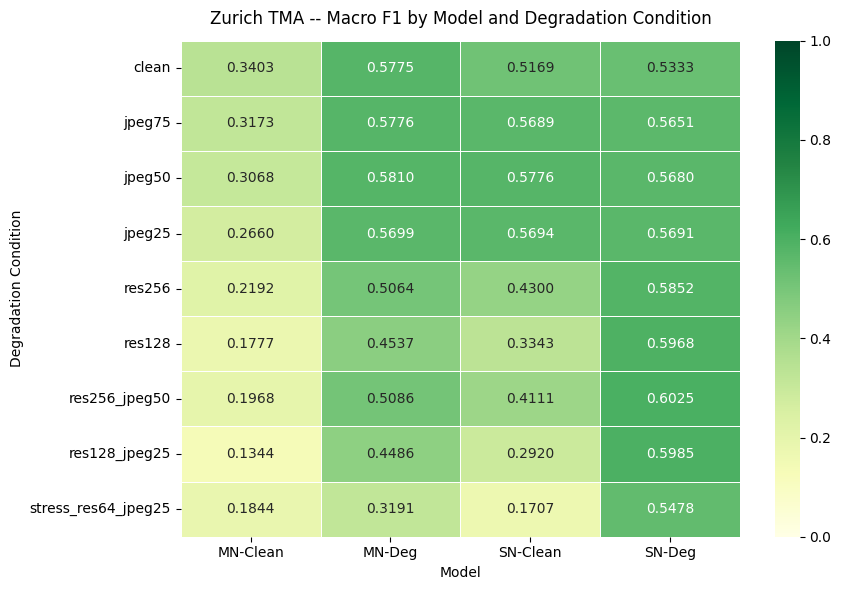


Mean macro F1 across all conditions:
  SN-Deg      : 0.5740
  MN-Deg      : 0.5047
  SN-Clean    : 0.4301
  MN-Clean    : 0.2381


In [69]:
# Heat-map of the generalisation table
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(results_df.astype(float), annot=True, fmt='.4f', cmap='YlGn',
            vmin=0, vmax=1, linewidths=0.5, ax=ax)
ax.set_title('Zurich TMA -- Macro F1 by Model and Degradation Condition', pad=12)
ax.set_xlabel('Model'); ax.set_ylabel('Degradation Condition')
plt.tight_layout(); plt.show()

mean_f1 = results_df.mean().sort_values(ascending=False)
print('\nMean macro F1 across all conditions:')
for name, v in mean_f1.items():
    print(f'  {name:<12s}: {v:.4f}')

### Analysis: Zurich generalisation table

Moving to Zurich costs every model accuracy, even before any degradation is applied. On clean Zurich images, MN-Clean drops from 0.672 on SICAPv2 validation to 0.340, SN-Clean from 0.732 to 0.517, MN-Deg to 0.578 and SN-Deg to 0.533. Part of this is a change in class mix. Zurich is dominated by G3 (1,173 of 3,055 patches), while NC and G4 dominate SICAPv2 validation. Part is the usual shift between institutions in staining, scanning and tissue preparation.

Degradation training clearly helps once the images get worse. SN-Deg is nearly flat across all nine conditions, staying between 0.53 and 0.60 and scoring 0.548 under the harshest condition, with the best mean of the four (0.574). SN-Clean holds up under JPEG compression alone but falls to 0.334 at res128 and 0.171 under the stress condition. Resolution loss causes far more damage than JPEG compression for every clean-trained model.

Two results stand out. First, MN-Deg beats MN-Clean by a wide margin even on clean Zurich images (0.578 against 0.340), so the augmentation seems to make MobileNet less sensitive to the change of dataset as well as to image quality. Second, several models score slightly higher under mild JPEG compression than on clean images. SN-Clean, for example, goes from 0.517 to 0.578 at jpeg50. One possible reading is that compression removes fine, scanner-specific texture that differs between the two datasets, but we have not tested this directly.

## Classification Reports -- Zurich, Clean Condition

Per-class precision, recall, and F1 on the clean Zurich set.
Useful for diagnosing which Gleason grades are hardest to classify.

In [70]:
for mname, (model, _) in MODELS.items():
    yt, yp = evaluate_on_condition(model, zurich_df, ZURICH_IMGS, 'clean')
    print_cls_report(yt, yp, title=f'{mname} -- Zurich Clean Classification Report')


MN-Clean -- Zurich Clean Classification Report
              precision    recall  f1-score   support

          NC       0.28      0.17      0.21       460
          G3       0.89      0.34      0.49      1173
          G4       0.50      0.29      0.37      1006
          G5       0.18      0.76      0.29       416

    accuracy                           0.35      3055
   macro avg       0.46      0.39      0.34      3055
weighted avg       0.57      0.35      0.38      3055


MN-Deg -- Zurich Clean Classification Report
              precision    recall  f1-score   support

          NC       0.73      0.60      0.66       460
          G3       0.83      0.45      0.59      1173
          G4       0.48      0.81      0.61      1006
          G5       0.50      0.43      0.46       416

    accuracy                           0.59      3055
   macro avg       0.64      0.57      0.58      3055
weighted avg       0.66      0.59      0.59      3055


SN-Clean -- Zurich Clean Classifica

### Analysis: Zurich per-class results, clean condition

The per-class reports show that macro F1 hides very different failure modes. Each model on clean Zurich has a bias toward one class:

- MN-Clean predicts G5 far too often. G5 recall is 0.76, but precision is only 0.18, and NC recall falls to 0.17.
- SN-Clean predicts NC far too often. NC recall is 0.98 with a precision of 0.34, and G3 recall drops to 0.33.
- MN-Deg leans toward G4, with a G4 recall of 0.81 at a precision of 0.48.
- SN-Deg leans toward G3, with a G3 recall of 0.85 but a G4 recall of only 0.27.

None of these biases appeared on SICAPv2 validation, where each model's errors were spread across classes. A shift in staining or scanning can move all of a model's features in the same direction, which would explain why each model collapses toward a single class. The confusion matrices further down show exactly where the patches go.

## Classification Reports -- Zurich, Stress Condition (res64 + jpeg25)

The same per-class breakdown under the most severe degradation condition.
A large drop from the clean condition indicates poor robustness.

In [71]:
for mname, (model, _) in MODELS.items():
    yt, yp = evaluate_on_condition(model, zurich_df, ZURICH_IMGS, 'stress_res64_jpeg25')
    print_cls_report(yt, yp,
        title=f'{mname} -- Zurich Stress (res64+jpeg25) Classification Report')


MN-Clean -- Zurich Stress (res64+jpeg25) Classification Report
              precision    recall  f1-score   support

          NC       0.14      0.64      0.24       460
          G3       1.00      0.00      0.00      1173
          G4       0.47      0.15      0.23      1006
          G5       0.22      0.37      0.27       416

    accuracy                           0.20      3055
   macro avg       0.46      0.29      0.18      3055
weighted avg       0.59      0.20      0.15      3055


MN-Deg -- Zurich Stress (res64+jpeg25) Classification Report
              precision    recall  f1-score   support

          NC       0.27      0.95      0.42       460
          G3       0.94      0.10      0.18      1173
          G4       0.42      0.51      0.46      1006
          G5       0.50      0.13      0.21       416

    accuracy                           0.37      3055
   macro avg       0.53      0.42      0.32      3055
weighted avg       0.61      0.37      0.31      3055


SN-

### Analysis: Zurich per-class results, stress condition

Under the harshest condition (downscaled to 64 pixels, then JPEG quality 25), three of the four models stop distinguishing grades. SN-Clean predicts G4 for nearly every patch: G4 recall is 1.00, and G3 and G5 recall are both 0.00. MN-Clean finds no G3 at all. MN-Deg predicts NC for most patches, with an NC recall of 0.95 at a precision of 0.27 and a G3 recall of 0.10.

SN-Deg is the only model that still separates the classes. NC, G3 and G4 keep F1 scores between 0.59 and 0.71, and accuracy is 0.62, slightly higher than on clean Zurich (0.59). Its weak point is G5. Recall drops to 0.16, although precision stays high at 0.86. At 64 pixels, the nuclear and cellular detail that marks G5 is mostly gone, so the model calls G5 only when it is very sure.

## Confusion Matrices -- All 4 Models (Zurich, Clean)

Side-by-side confusion matrices make it easy to see which Gleason grades
are confused with each other and whether the pattern differs between
clean-trained and degradation-trained models.

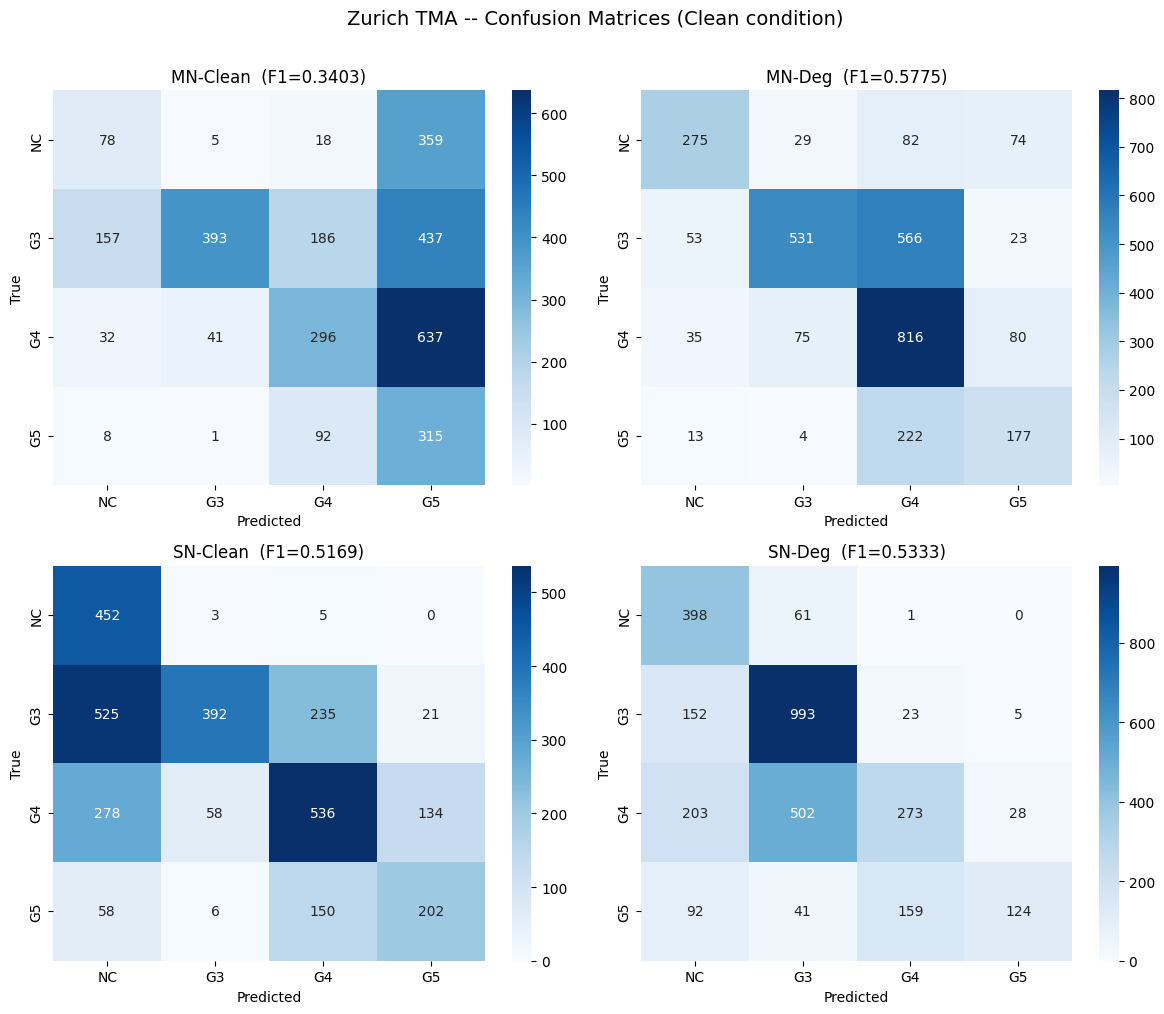

In [72]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (mname, (model, _)) in zip(axes.flat, MODELS.items()):
    yt, yp = evaluate_on_condition(model, zurich_df, ZURICH_IMGS, 'clean')
    cm = confusion_matrix(yt, yp, labels=list(range(NUM_CLASSES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    f1 = results[mname]['clean']
    ax.set_title(f'{mname}  (F1={f1:.4f})')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
fig.suptitle('Zurich TMA -- Confusion Matrices (Clean condition)', fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

### Analysis: Zurich confusion matrices, clean condition

The confusion matrices give the counts behind the biases described above.

MN-Clean sends 1,748 of the 3,055 patches to G5, including 637 true G4 patches, 437 true G3 patches and 359 of the 460 NC patches. SN-Clean does the opposite for NC. 525 true G3 patches and 278 true G4 patches are predicted as NC, which accounts for most of its low G3 recall.

The degradation-trained models make fewer cross-category errors of this kind, but each has its own G3 and G4 problem. MN-Deg predicts 566 true G3 patches as G4, while SN-Deg predicts 502 true G4 patches as G3. This is the same boundary that limited every model in the SICAPv2 ablations, and the change of dataset makes it worse. Even so, SN-Deg rarely mistakes tumour for benign tissue at the G3 level and keeps NC precision usable, which matters more clinically than a slip between neighbouring grades.

## Degradation Robustness Curves

Line chart ordered by degradation severity (left = clean, right = most degraded).
A flat curve indicates a model that is robust across image-quality conditions.

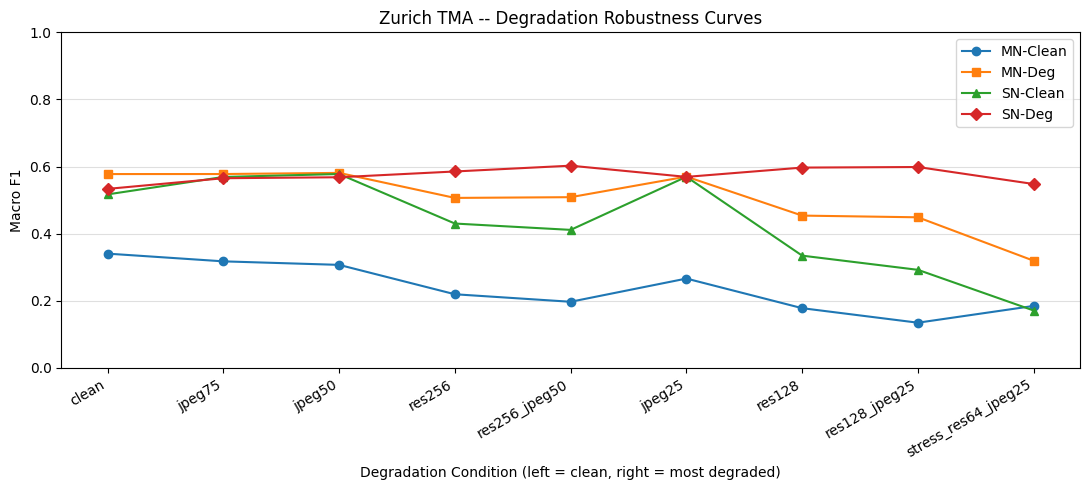

In [73]:
SEVERITY_ORDER = [
    'clean', 'jpeg75', 'jpeg50', 'res256',
    'res256_jpeg50', 'jpeg25', 'res128',
    'res128_jpeg25', 'stress_res64_jpeg25',
]
plot_conds = [c for c in SEVERITY_ORDER if c in results_df.index]

fig, ax = plt.subplots(figsize=(11, 5))
for mname, mk in zip(MODEL_NAMES, ['o', 's', '^', 'D']):
    vals = [results[mname][c] for c in plot_conds]
    ax.plot(plot_conds, vals, marker=mk, label=mname)
ax.set_xlabel('Degradation Condition (left = clean, right = most degraded)')
ax.set_ylabel('Macro F1')
ax.set_title('Zurich TMA -- Degradation Robustness Curves')
ax.set_xticklabels(plot_conds, rotation=30, ha='right')
ax.legend(); ax.set_ylim(0, 1.0); ax.grid(axis='y', alpha=0.4)
plt.tight_layout(); plt.show()

### Analysis: degradation robustness curves

The curves rank the four models clearly. SN-Deg is almost flat from left to right, starting at 0.533 on clean images and ending at 0.548 under the stress condition. MN-Deg holds steady through the JPEG conditions but drops once resolution falls, reaching 0.454 at res128 and 0.319 at the stress condition. SN-Clean follows MN-Deg for JPEG-only conditions and then falls further, ending at 0.171. MN-Clean is the weakest model throughout.

The dips line up with resolution loss. Each clean-trained model falls at res256 and res128 and partly recovers at jpeg25, which is a compression-only condition placed between them on the axis. Resolution is the degradation these models are least prepared for, and it is also the one degradation training fixes best.

Taken together, ShuffleNet with plain ImageNet pretraining and degradation-aware training is the most reliable of the four models on unseen data across image qualities. It is the best candidate for settings where slides are compressed or downsampled before analysis.

---
## Summary

All experiments complete. Results are persisted in `results_registry.json`. Checkpoints are saved in `capstone/checkpoints/empirical/ckpts/`.

In [74]:
reg = registry_load()
print('\n== EXPERIMENT REGISTRY SUMMARY ==')
for arch in ['mobilenet', 'shufflenet']:
    print(f'\n  {arch.upper()}')
    for key, entry in reg.get(arch, {}).items():
        print(f'    {key:<15s}  regime={entry["regime"]:<12s}  '
              f'val_f1={entry["val_f1"]:.4f}  ckpt={Path(entry["ckpt"]).name}')

print('\n== ZURICH GENERALISATION (mean macro F1 across all conditions) ==')
for name, v in results_df.mean().sort_values(ascending=False).items():
    print(f'  {name:<12s}: {v:.4f}')

print('\nDone.')


== EXPERIMENT REGISTRY SUMMARY ==

  MOBILENET
    ExpA             regime=clean         val_f1=0.5051  ckpt=mobilenet_ExpA_clean.pth
    ExpB             regime=clean         val_f1=0.6571  ckpt=mobilenet_ExpB_clean.pth
    ExpC             regime=clean         val_f1=0.6623  ckpt=mobilenet_ExpC_clean.pth
    ExpD             regime=clean         val_f1=0.6568  ckpt=mobilenet_ExpD_clean.pth
    ExpE             regime=clean         val_f1=0.6721  ckpt=mobilenet_ExpE_clean.pth
    ExpF             regime=clean         val_f1=0.6709  ckpt=mobilenet_ExpF_clean.pth
    degradation      regime=degradation   val_f1=0.6653  ckpt=mobilenet_degradation_degradation.pth

  SHUFFLENET
    ExpA             regime=clean         val_f1=0.6106  ckpt=shufflenet_ExpA_clean.pth
    ExpB             regime=clean         val_f1=0.7324  ckpt=shufflenet_ExpB_clean.pth
    ExpC             regime=clean         val_f1=0.7316  ckpt=shufflenet_ExpC_clean.pth
    ExpD             regime=clean         val_f1=0.7